# III. 벡터 Burgers VPINN — 5개 시드와 적분점 배치 실험

# 정상상태 2D vector Burgers 방정식 — 공간 의존 우변 VPINN 한글 실습
### 단위원, $\mathbf f(x,y)=(-1,-\sin(\pi y))$, 영 Dirichlet 경계조건

이 노트북은 다음 두 비선형 방정식을 함께 풉니다.
$$
\boxed{\begin{aligned}
u u_x+v u_y-\varepsilon(u_{xx}+u_{yy})&=-1,\\
u v_x+v v_y-\varepsilon(v_{xx}+v_{yy})&=-\sin(\pi y),
\end{aligned}\quad x^2+y^2<1,\qquad u=v=0\text{ on }x^2+y^2=1.}
$$
기본 확산계수는 $\varepsilon=0.1$입니다. 시간 변수와 압력은 없으며, $u_x+v_y=0$을 요구하지 않습니다. 첫 번째 우변은 상수이고 두 번째 우변은 공간좌표 y의 함수입니다. $f_2(x,0)=0$, $f_2(x,0.5)=-1$, $f_2(x,-0.5)=1$입니다.

**VPINN의 학습 원리:** 신경망은 $(x,y)\mapsto(u_\theta,v_\theta)$를 직접 근사하고, 고정 시험함수에 대해 적분한 **약형 잔차만** 최소화합니다. 두 방정식은 대류 속도 (u,v)를 통해 결합됩니다. 강형 PDE 잔차와 FEM 해는 사후 검증에 사용하고 학습 손실에는 넣지 않습니다.

**두 성분을 구분하십시오.** 이번 우변은 두 성분이 다르므로 $u=v$를 기대하거나 강제하지 않습니다. $u-v$ 지도와 RMS는 물리적인 성분 차이이며 정확도 오차가 아닙니다. 정확도는 동일한 공간 의존 우변으로 새로 계산한 결합 P3 FEM 해와 비교합니다.

**실행:** 프로젝트의 현재 프로젝트의 `.venv` Python 커널을 선택하고 **커널 재시작 후 모든 셀 실행(Restart Kernel and Run All)**을 실행하십시오. Python·MATLAB 원본 소스와 두 개의 새 P3 참조해가 이 파일 안에 들어 있습니다. 패키지는 `numpy scipy torch matplotlib ipykernel`이며 자동 검증에는 `nbformat nbclient`도 사용합니다.

기본 실행에는 MATLAB이 필요하지 않습니다. 참조해를 다시 계산하려면 2번 셀에서 `REBUILD_REFERENCES=True`를 선택하고 설치된 MATLAB 실행 파일을 `MATLAB_EXE`에 지정하십시오. Python이 MATLAB을 자동 호출하므로 MATLAB 창을 직접 열 필요는 없습니다. 결과는 `vector_vpinn_sine_outputs/` 아래에 저장됩니다.

기본 VPINN은 원본의 Gauss 적분 규칙을 사용합니다. 15절에서 저장된 기본 Gauss / 5,120점 / seed 2026 모델을 불러오고, 16–30절에서 기본 검증과 그림을 확인합니다. 랜덤 collocation(약형 적분점) 세 가지와 경계 강조 Gauss는 31절 이후의 비교 실험입니다. 36절은 Gauss 기준의 시험공간·epsilon 확장입니다. 동봉된 study.py와 reference_core.py를 같은 폴더에 두십시오.

## 1. 패키지와 노트북 경로

필요한 패키지만 불러오며, 옆에 있는 `.py` 파일은 import하지 않습니다. 이후 셀에서 함수를 직접 정의합니다. 노트북이 자신의 저장 파일을 찾는 이유는 메타데이터에 내장된 참조 바이너리와 원본 소스를 읽기 위해서입니다. 파일을 옮겨 찾지 못하면 `NOTEBOOK_PATH`를 직접 지정하십시오.

Matplotlib은 인라인 모드로 사용하므로 모든 그림을 노트북 안에서 볼 수 있습니다. 인터프리터 경로를 출력하여 의도한 Python 환경을 쓰는지 확인합니다. 계산은 CPU float64이며 재현성을 위해 PyTorch 스레드 수를 1로 둡니다. 노트북 출력 폴더는 현재 파일 옆에 생성합니다.

In [1]:
import os,sys,json,base64,hashlib,csv,time,shutil,subprocess,tempfile
from pathlib import Path
from types import SimpleNamespace
from datetime import datetime
from zoneinfo import ZoneInfo
os.environ.setdefault('MPLCONFIGDIR',str(Path(tempfile.gettempdir())/'vector_vpinn_mpl'))
import numpy as np
import torch
from torch import nn
from scipy.io import loadmat
from scipy.special import eval_jacobi
from scipy.spatial import ConvexHull
from numpy.polynomial.legendre import leggauss
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize,LogNorm
from matplotlib.tri import Triangulation
from IPython.display import display,Markdown
get_ipython().run_line_magic('matplotlib','inline')
torch.set_num_threads(1)
NOTEBOOK_PATH=next((p for p in [Path.cwd()/'VPINN_sampling_study.ipynb',Path.cwd()/'VPINN_sampling_study_20261118'/'VPINN_sampling_study.ipynb'] if p.is_file()),None)
if NOTEBOOK_PATH is None:
    candidates=[Path.cwd()/'Vector_Burgers2D_VPINN_Sine_KO.ipynb',
                Path.cwd()/'vector_burgers_vpinn_sine'/'Vector_Burgers2D_VPINN_Sine_KO.ipynb',
                Path.cwd()/'output'/'vector_burgers_vpinn_sine'/'Vector_Burgers2D_VPINN_Sine_KO.ipynb']
    NOTEBOOK_PATH=next((p.resolve() for p in candidates if p.is_file()),None)
if NOTEBOOK_PATH is None:raise FileNotFoundError('NOTEBOOK_PATH에 이 노트북의 저장 경로를 지정하십시오.')
NOTEBOOK_PATH=Path(NOTEBOOK_PATH).resolve()
os.chdir(NOTEBOOK_PATH.parent)
sys.path.insert(0,str(NOTEBOOK_PATH.parent))
BUNDLE=json.loads(NOTEBOOK_PATH.read_text(encoding='utf-8'))['metadata']['vector_vpinn_bundle']
WORK_DIR=NOTEBOOK_PATH.parent/'vector_vpinn_sine_outputs';WORK_DIR.mkdir(exist_ok=True)
print('Python:',sys.executable,'| PyTorch:',torch.__version__)
print('노트북:',NOTEBOOK_PATH,'\n출력:',WORK_DIR)

Python: <local-project>\.venv\Scripts\python.exe | PyTorch: 2.15.0+cpu
노트북: <local-project>\VPINN_sampling_study_20261118\VPINN_sampling_study.ipynb 
출력: <local-project>\VPINN_sampling_study_20261118\vector_vpinn_sine_outputs


## 2. 공간 의존 우변, 시험공간, 학습 및 MATLAB 설정

우변은 이름 `FORCING='minus_one_minus_sin_pi_y'`로 식별합니다. 이 문자열을 수식으로 임의 해석하지 않으며, 7번 셀의 `source_tensor`에서 정확히 $[-1,-\sin(\pi y)]$를 계산합니다. MATLAB의 하중 조립도 같은 식을 각 요소의 물리 적분점에서 평가합니다. 설정과 참조 파일에 같은 식별자를 저장하여 예전 상수 우변 참조해를 섞지 않습니다.

두 성분의 경계값은 0, epsilon은 0.1입니다. 네트워크는 너비 32의 은닉층 세 개, Adam 3,000회와 L-BFGS 최대 1,500회를 기본값으로 사용합니다. 반복 횟수는 물리적인 시간 단계가 아닙니다. 시험 다항식 차수 18은 스칼라 시험함수 190개이며 두 성분을 합하면 잔차 380개입니다. 적분점은 40×128=5,120개입니다. 검증에는 56×190개 적분점과 차수 22의 시험함수 276개를 사용합니다.

내장 참조해는 현재 우변과 epsilon=0.1, h=0.04/0.02로 새로 계산했습니다. epsilon 또는 메시 크기를 바꾸면 `REBUILD_REFERENCES=True`로 재계산하십시오. 우변의 함수 형태 자체를 바꿀 때는 Python과 MATLAB의 함수 및 식별자를 함께 수정해야 합니다. `MATLAB_EXE=None`은 자동 탐색이며 경로를 직접 지정할 수도 있습니다. DistMesh를 찾지 못하면 MATLAB 내장 삼각분할의 polar 메시로 전환합니다.

In [2]:
EPSILON=.1
FORCING='minus_one_minus_sin_pi_y'
CONFIG={'epsilon':EPSILON,'forcing':FORCING,'seed':2026,'width':32,'depth':3,
        'test_degree':18,'n_radial':40,'n_angular':128,
        'adam_steps':3000,'adam_lr':.001,'lbfgs_steps':1500,'lbfgs_lr':1.0,
        'validation_degree':22,'validation_radial':56,'validation_angular':160,'eval_points':10000}
H_COARSE,H_FINE=.04,.02
REBUILD_REFERENCES=False
MATLAB_EXE=None  # 예: '/Applications/MATLAB_R2024b.app/bin/matlab'
if MATLAB_EXE is None:
    MATLAB_EXE=shutil.which('matlab')
    if MATLAB_EXE is None:
        MATLAB_EXE=next((str(p) for p in [Path('/Applications/MATLAB_R2024b.app/bin/matlab'),
                                         Path('/Applications/MATLAB_R2025b.app/bin/matlab')] if p.is_file()),None)
DISTMESH_PATH=Path('/Users/cjung/Library/CloudStorage/Dropbox/Teaching/Graduate/Numerical PDE2/2026 - fem/programming hw/DistMesh-main/src')
MESH_METHOD='distmesh' if DISTMESH_PATH.is_dir() else 'polar'
assert EPSILON>0 and np.isfinite(EPSILON)
assert FORCING=='minus_one_minus_sin_pi_y'
assert CONFIG['test_degree']>=0 and CONFIG['validation_degree']>CONFIG['test_degree']
assert CONFIG['validation_radial']>CONFIG['n_radial'] and CONFIG['validation_angular']>CONFIG['n_angular']
stamp=datetime.now(ZoneInfo('Asia/Seoul')).strftime('%Y%m%d_%H%M%S_%f')
RUN_DIR=WORK_DIR/'runs'/f'vector_vpinn_sine_{stamp}'
MATLAB_DIR=WORK_DIR/'matlab';MATLAB_DIR.mkdir(exist_ok=True)
REFERENCE_DIR=WORK_DIR/'reference';REFERENCE_DIR.mkdir(exist_ok=True)
print('방정식: (u*d_x+v*d_y)[u,v]-epsilon*Delta[u,v]=[-1,-sin(pi*y)]')
print('MATLAB:',MATLAB_EXE,'| 재계산:',REBUILD_REFERENCES)

방정식: (u*d_x+v*d_y)[u,v]-epsilon*Delta[u,v]=[-1,-sin(pi*y)]
MATLAB: None | 재계산: False


## 3. MATLAB 소스: 두 성분의 결합 P3 Newton 솔버

참조해는 두 개의 독립된 스칼라 선형 풀이가 아니라, u와 v가 대류 속도로 함께 들어가는 결합 비선형 시스템의 해입니다. 확산항을 부분적분한 P3 Galerkin 약형을 사용하며, 경계 자유도는 0으로 고정합니다. Newton Jacobian은 네 블록을 갖습니다. 예를 들어 첫 방정식의 선형화는
$$
\delta(u u_x+v u_y)=(\delta u)u_x+u\partial_x\delta u+(\delta v)u_y+v\partial_y\delta u
$$
입니다. 두 번째 방정식도 두 성분에 대해 모두 미분해야 합니다.

코드는 서로 다른 임의의 u,v 상태에서 전체 Jacobian을 중심 유한차분으로 확인합니다. 우변을 단계적으로 늘리고 감쇠 Newton 선 탐색을 수행하여 상대 대수 잔차가 1e-10 아래로 내려간 결과만 저장합니다. P3 대류 적분항은 총 차수 8이며 6×6 Gauss–Duffy 적분을 사용합니다. 두 번째 하중은 비다항식이므로 이 적분이 정확하다고 가정하지 않습니다. 각 적분점의 물리 좌표 y에서 -sin(pi*y)를 계산하여 Vᵀ(W·f)를 조립하고, 메시 세분화로 참조해의 변화를 확인합니다. 아래 셀은 소스를 문자열로 저장하며 실제 실행은 다음 셀의 옵션으로 선택합니다.

In [3]:
MATLAB_SOURCE=r"""
function info=fem_p3_vector_burgers(epsilon,h,filename,forcing,mesh_method)
% 정상상태 vector Burgers: (u,v).grad(u,v)-epsilon*Delta(u,v)=forcing.
% 압력이나 div(u,v)=0 제약은 없습니다. 두 성분의 경계값은 모두 0입니다.
if nargin<1, epsilon=.1; end
if nargin<2, h=.04; end
if nargin<3, filename='p3_vector_burgers_sine.mat'; end
if nargin<4, forcing='minus_one_minus_sin_pi_y'; end
if nargin<5, mesh_method='distmesh'; end
validateattributes(epsilon,{'numeric'},{'scalar','positive','finite'});
validateattributes(h,{'numeric'},{'scalar','positive','<=',.5,'finite'});
assert(strcmp(forcing,'minus_one_minus_sin_pi_y'),'Expected f=(-1,-sin(pi*y)).');
forcing=char(forcing);
forcing_formula='[-1,-sin(pi*y)]';
assert(~isfile(filename),'Output exists; choose a new filename.');
rng(2026, 'twister');
mesh_start = tic;
if strcmp(mesh_method, 'distmesh')
    assert(exist('distmesh2d','file') == 2, 'Add DistMesh-main/src to the MATLAB path.');
    fd = @(p) sqrt(sum(p.^2,2))-1;
    [vertices,tri] = distmesh2d(fd,@huniform,h,[-1,-1;1,1],[]);
elseif strcmp(mesh_method, 'polar')
    vertices = [0,0];
    nr = ceil(1/h);
    for j = 1:nr
        r = j/nr;
        n = max(8,ceil(2*pi*r/h));
        theta = 2*pi*(0:n-1)'/n;
        vertices = [vertices; r*cos(theta),r*sin(theta)]; %#ok<AGROW>
    end
    tri = delaunay(vertices(:,1),vertices(:,2));
else
    error('mesh_method must be distmesh or polar');
end
% Project only boundary VERTICES to the exact circle. Edge nodes remain on chords.
all_edges = sort([tri(:,[1,2]);tri(:,[2,3]);tri(:,[3,1])],2);
[edges,~,edge_map] = unique(all_edges,'rows');
edge_counts = accumarray(edge_map,1);
boundary_edges = find(edge_counts == 1);
bv = unique(edges(boundary_edges,:));
vertices(bv,:) = vertices(bv,:)./sqrt(sum(vertices(bv,:).^2,2));
nt = size(tri,1); nv = size(vertices,1); ne = size(edges,1);
% Use one canonical direction for each edge; elements may reverse that direction.
edge1 = nv+(1:ne)';
edge2 = nv+ne+(1:ne)';
centroid = nv+2*ne+(1:nt)';
p = [vertices; (2*vertices(edges(:,1),:)+vertices(edges(:,2),:))/3; ...
               (vertices(edges(:,1),:)+2*vertices(edges(:,2),:))/3; ...
               (vertices(tri(:,1),:)+vertices(tri(:,2),:)+vertices(tri(:,3),:))/3];
emap = reshape(edge_map,nt,3);
t = [tri,centroid,edge1(emap(:,1)),edge2(emap(:,1)), ...
                  edge1(emap(:,2)),edge2(emap(:,2)),edge1(emap(:,3)),edge2(emap(:,3))];
b = unique([bv;edge1(boundary_edges);edge2(boundary_edges)]);
mesh_seconds = toc(mesh_start);

assembly_start=tic;
[q,w]=triangle_rule(6); [M,Mxi,Meta]=monomials(q);
n=size(p,1); nq=numel(w); I=zeros(100*nt,1); J=I; kval=I;
F=zeros(n,2); Vcache=zeros(nq,10,nt); Xcache=Vcache; Ycache=Vcache; Wcache=zeros(nq,nt);
for e=1:nt
    nd=t(e,:); v=p(nd(1:3),:); Jac=[v(2,:)-v(1,:);v(3,:)-v(1,:)]';
    Vnode=monomials((p(nd,:)-v(1,:))/Jac');
    V=M/Vnode; Dxi=Mxi/Vnode; Deta=Meta/Vnode; invJ=Jac\eye(2);
    Dx=invJ(1,1)*Dxi+invJ(2,1)*Deta; Dy=invJ(1,2)*Dxi+invJ(2,2)*Deta;
    W=w*abs(det(Jac)); Ke=epsilon*(Dx'*(W.*Dx)+Dy'*(W.*Dy));
    physical_points=q*Jac'+v(1,:);
    rhs_values=[-ones(nq,1),-sin(pi*physical_points(:,2))];
    F(nd,:)=F(nd,:)+V'*(W.*rhs_values);
    [ii,jj]=ndgrid(nd,nd); loc=(e-1)*100+(1:100);
    I(loc)=ii(:);J(loc)=jj(:);kval(loc)=Ke(:);
    Vcache(:,:,e)=V;Xcache(:,:,e)=Dx;Ycache(:,:,e)=Dy;Wcache(:,e)=W;
end
K=sparse(I,J,kval,n,n); free=setdiff((1:n)',b); free2=[free;free+n];
F=F(:); assembly_seconds=toc(assembly_start);
% 서로 다른 u,v 상태에서 네 블록 Jacobian 전체를 유한차분으로 검증합니다.
check_start=tic;
trial=zeros(2*n,1); direction=trial;
trial(free2)=.05*randn(numel(free2),1);direction(free2)=randn(numel(free2),1);
[~,JJ]=nonlinear_system(trial,true); delta=1e-6;
fd=(nonlinear_system(trial+delta*direction,false)-nonlinear_system(trial-delta*direction,false))/(2*delta);
jd=JJ*direction;
jacobian_check_relative=norm(fd(free2)-jd(free2))/norm(jd(free2));
assert(jacobian_check_relative<1e-7,'Coupled Jacobian finite difference check failed.');
jacobian_check_seconds=toc(check_start);

solve_start=tic; state=zeros(2*n,1); newton_history=[];
for load_factor=[.25,.5,.75,1]
    target=load_factor*F; scale=max(norm(target(free2)),1e-14);converged=false;
    for iter=0:40
        [R,JJ]=nonlinear_system(state,true);R=R-target;
        relative=norm(R(free2))/scale;
        fprintf('vector load=%.2f Newton=%d residual=%.3e\n',load_factor,iter,relative);
        if relative<1e-10
            newton_history(end+1,:)=[load_factor,iter,relative,0]; %#ok<AGROW>
            converged=true;break
        end
        if iter==40, break; end
        step=zeros(2*n,1);step(free2)=-JJ(free2,free2)\R(free2);
        damping=1;accepted=false;
        for ls=1:20
            candidate=state+damping*step;
            candidate_residual=nonlinear_system(candidate,false)-target;
            if norm(candidate_residual(free2))<=(1-1e-4*damping)*norm(R(free2))
                accepted=true;break
            end
            damping=damping/2;
        end
        assert(accepted,'Coupled Newton line search failed.');
        newton_history(end+1,:)=[load_factor,iter,relative,damping]; %#ok<AGROW>
        state=candidate;
    end
    assert(converged,'Newton convergence failure; no reference saved.');
end
solve_seconds=toc(solve_start);
R=nonlinear_system(state,false)-F;
relative_algebraic_residual=norm(R(free2))/max(norm(F(free2)),realmin);
U=reshape(state,n,2);component_difference_max=max(abs(U(:,1)-U(:,2)));
problem_id='steady_vector_burgers_2d';advection_form='(u*d_x+v*d_y)[u,v]';
boundary_value=[0,0];element_degree=3;geometry='straight_sided_polygon_approximating_unit_disk';
parent=fileparts(filename);if ~isempty(parent)&&~isfolder(parent),mkdir(parent);end
save(filename,'p','t','U','epsilon','forcing','forcing_formula','problem_id','advection_form','boundary_value', ...
    'element_degree','geometry','b','h','mesh_method','mesh_seconds','assembly_seconds','solve_seconds', ...
    'relative_algebraic_residual','newton_history','jacobian_check_relative','jacobian_check_seconds', ...
    'component_difference_max','-v7');
info=struct('file',filename,'nodes_per_component',n,'total_dofs',2*n,'elements',nt,'h',h, ...
    'relative_algebraic_residual',relative_algebraic_residual,'jacobian_check_relative',jacobian_check_relative, ...
    'component_difference_max',component_difference_max,'min_u',min(U(:,1)),'min_v',min(U(:,2)), ...
    'mesh_seconds',mesh_seconds,'assembly_seconds',assembly_seconds,'solve_seconds',solve_seconds);
disp(info)

    function [res,jac]=nonlinear_system(z,with_jacobian)
        uu=z(1:n);vv=z(n+1:end);ru=K*uu;rv=K*vv;
        if with_jacobian, j11=zeros(100*nt,1);j12=j11;j21=j11;j22=j11;end
        for el=1:nt
            nd=t(el,:);V=Vcache(:,:,el);Dx=Xcache(:,:,el);Dy=Ycache(:,:,el);W=Wcache(:,el);
            u=V*uu(nd);v=V*vv(nd);ux=Dx*uu(nd);uy=Dy*uu(nd);vx=Dx*vv(nd);vy=Dy*vv(nd);
            ru(nd)=ru(nd)+V'*(W.*(u.*ux+v.*uy));
            rv(nd)=rv(nd)+V'*(W.*(u.*vx+v.*vy));
            if with_jacobian
                A=V'*(W.*(ux.*V+u.*Dx+v.*Dy)); B=V'*(W.*(uy.*V));
                C=V'*(W.*(vx.*V));D=V'*(W.*(vy.*V+u.*Dx+v.*Dy));
                loc=(el-1)*100+(1:100);j11(loc)=A(:);j12(loc)=B(:);j21(loc)=C(:);j22(loc)=D(:);
            end
        end
        res=[ru;rv];
        if with_jacobian
            jac=[K+sparse(I,J,j11,n,n),sparse(I,J,j12,n,n);sparse(I,J,j21,n,n),K+sparse(I,J,j22,n,n)];
        else, jac=[];end
    end
end

function [M,Dx,Dy] = monomials(q)
x = q(:,1); y = q(:,2); z = zeros(size(x)); o = ones(size(x));
M = [o,x,y,x.^2,x.*y,y.^2,x.^3,x.*y.^2,x.^2.*y,y.^3];
Dx = [z,o,z,2*x,y,z,3*x.^2,y.^2,2*x.*y,z];
Dy = [z,z,o,z,x,2*y,z,2*x.*y,x.^2,3*y.^2];
end

function [q,w] = triangle_rule(n)
% Golub-Welsch Gauss-Legendre nodes on [0,1], then Duffy transform.
k = (1:n-1)'; beta = k./sqrt(4*k.^2-1);
[V,D] = eig(diag(beta,1)+diag(beta,-1));
[s,idx] = sort(diag(D)); w1 = V(1,idx)'.^2;
s = (s+1)/2;
[a,b] = ndgrid(s,s); [wa,wb] = ndgrid(w1,w1);
q = [a(:),(1-a(:)).*b(:)];
w = wa(:).*wb(:).*(1-a(:));
end
"""
(MATLAB_DIR/'fem_p3_vector_burgers.m').write_text(MATLAB_SOURCE,encoding='utf-8')
print('MATLAB 소스 저장:',MATLAB_DIR)

MATLAB 소스 저장: <local-project>\VPINN_sampling_study_20261118\vector_vpinn_sine_outputs\matlab


## 4. 새 참조해 복원 또는 MATLAB 자동 실행

기본 실행에서는 현재 공간 의존 우변으로 실제 계산한 두 P3 참조해를 복원합니다. Base64는 저장 형식이며 SHA-256으로 바이트 일치를 확인합니다. epsilon, 우변 식별자, 메시 크기를 검사하여 이전 상수 우변의 데이터를 재사용하지 않습니다.

재계산을 선택하면 Python이 MATLAB 배치 명령을 실행하여 두 메시의 결합 Newton 문제를 풉니다. 완료 후 로그를 출력하고 오류가 나면 중단합니다. 새 참조해는 시각이 포함된 이름으로 저장합니다. MATLAB에서 직접 실행하는 형태는 `fem_p3_vector_burgers(.1,.02,'new.mat','minus_one_minus_sin_pi_y','distmesh')`입니다. MATLAB Engine Python 패키지는 필요하지 않습니다.

In [4]:
def matlab_quote(value):return "'"+str(value).replace("'","''")+"'"
if REBUILD_REFERENCES:
    if MATLAB_EXE is None:raise RuntimeError('2번 셀에서 MATLAB_EXE를 지정하십시오.')
    COARSE_REF=REFERENCE_DIR/f'vector_coarse_{stamp}.mat';FINE_REF=REFERENCE_DIR/f'vector_fine_{stamp}.mat'
    commands=[f'addpath({matlab_quote(MATLAB_DIR)});',"set(0,'DefaultFigureVisible','off');"]
    if MESH_METHOD=='distmesh':commands.append(f'addpath({matlab_quote(DISTMESH_PATH)});')
    for h,path in ((H_COARSE,COARSE_REF),(H_FINE,FINE_REF)):
        commands.append(f'fem_p3_vector_burgers({EPSILON:.17g},{h:.17g},{matlab_quote(path)},'
                        f'{matlab_quote(FORCING)},{matlab_quote(MESH_METHOD)});')
    commands.append('close all;')
    print('MATLAB 결합 Newton 계산 중입니다. 완료 후 로그가 표시됩니다.')
    result=subprocess.run([str(MATLAB_EXE),'-batch',' '.join(commands)],text=True,capture_output=True,timeout=1800)
    print(result.stdout)
    if result.returncode:raise RuntimeError(result.stderr or 'MATLAB 계산 실패')
else:
    if (EPSILON,H_COARSE,H_FINE,FORCING)!=(.1,.04,.02,'minus_one_minus_sin_pi_y'):
        raise ValueError('물리 조건/메시를 바꾸면 REBUILD_REFERENCES=True로 참조해를 다시 계산하십시오.')
    for name,entry in BUNDLE['references'].items():
        payload=base64.b64decode(entry['base64'],validate=True)
        assert hashlib.sha256(payload).hexdigest()==entry['sha256']
        destination=REFERENCE_DIR/name
        if destination.exists() and destination.read_bytes()!=payload:raise ValueError(f'다른 기존 참조 파일: {destination}')
        if not destination.exists():destination.write_bytes(payload)
    COARSE_REF=REFERENCE_DIR/'p3_vector_burgers_sine_eps0p1_h0p04.mat'
    FINE_REF=REFERENCE_DIR/'p3_vector_burgers_sine_eps0p1_h0p02.mat'
print('참조 파일:',COARSE_REF,FINE_REF,sep='\n')

참조 파일:
<local-project>\VPINN_sampling_study_20261118\vector_vpinn_sine_outputs\reference\p3_vector_burgers_sine_eps0p1_h0p04.mat
<local-project>\VPINN_sampling_study_20261118\vector_vpinn_sine_outputs\reference\p3_vector_burgers_sine_eps0p1_h0p02.mat


## 5. P3 벡터 해 평가와 오차 노름

참조 파일의 U는 N×2 배열입니다. 두 성분을 각각 실제 3차 요소 다항식으로 평가하며 선형 보간으로 바꾸지 않습니다. MATLAB의 1부터 시작하는 절점 번호를 Python 인덱스로 변환하고, 문제 식별자·확산계수·공간 의존 우변 식별자·경계값·Newton 수렴 정보를 검사합니다. 요소가 직선 삼각형이라는 조건도 확인합니다.

벡터 L2 오차는 $\sqrt{\sum_q w_q[(u_\theta-u_h)^2+(v_\theta-v_h)^2]}$를 참조 벡터의 L2 노름으로 나눕니다. 벡터 L∞는 표본점에서 유클리드 벡터 길이의 최대값을 사용합니다. u,v 성분별 상대 오차도 별도로 계산합니다. 표본 L∞는 연속 영역 전체의 상한이 아니며, FEM 다각형 밖에서는 외삽하지 않습니다.

In [5]:
def monomials(xy):
    """Same complete cubic space as P3 reference triangle, in local coordinates."""
    x, y = np.asarray(xy).T
    return np.column_stack((np.ones_like(x), x, y, x*x, x*y, y*y,
                            x**3, x*y*y, x*x*y, y**3))


def triangle_rule(order=6):
    """Positive tensor Gauss/Duffy rule on (0,0),(1,0),(0,1); weights sum to 1/2."""
    if order < 2:
        raise ValueError("Quadrature order must be >= 2")
    s, w = leggauss(order)
    s, w = (s+1)/2, w/2
    a, b = np.meshgrid(s, s, indexing="ij")
    wa, wb = np.meshgrid(w, w, indexing="ij")
    return np.column_stack((a.ravel(), ((1-a)*b).ravel())), (wa*wb*(1-a)).ravel()


class P3VectorReference:
    """MATLAB columns 1:3 are vertices; columns 4:10 can use any nodal ordering.

    All ten nodes must be affine P3 nodes. Curved/isoparametric geometry is rejected.
    Required metadata prevents comparison with a different PDE or forcing vector.
    """
    def __init__(self, path, epsilon, forcing='minus_one_minus_sin_pi_y'):
        self.path = str(Path(path).resolve())
        try:
            data = loadmat(path, squeeze_me=True)
        except NotImplementedError as exc:
            raise ValueError("Save MATLAB reference with '-v7', not '-v7.3'.") from exc
        required = ("p", "t", "U", "epsilon", "problem_id", "advection_form", "forcing", "boundary_value", "relative_algebraic_residual")
        missing = [k for k in required if k not in data]
        if missing:
            raise ValueError(f"필수 MATLAB 필드가 없습니다: {missing}. matlab/fem_p3_vector_burgers.m을 사용하십시오.")
        if not np.isclose(float(data["epsilon"]), epsilon, rtol=1e-12, atol=1e-14):
            raise ValueError("FEM 참조해와 VPINN의 epsilon이 다릅니다.")
        if str(data["problem_id"]).strip() != "steady_vector_burgers_2d" or str(data["advection_form"]).strip() != "(u*d_x+v*d_y)[u,v]":
            raise ValueError("Reference must solve the steady 2D vector Burgers equation")
        self.algebraic_residual = float(data["relative_algebraic_residual"])
        if not np.isfinite(self.algebraic_residual) or self.algebraic_residual > 1e-7:
            raise ValueError("The nonlinear FEM reference has not converged sufficiently")
        if not np.array_equal(np.asarray(data["boundary_value"]).ravel(),[0,0]):
            raise ValueError("Both boundary components must be zero")
        if not isinstance(forcing,str) or str(data['forcing']).strip()!=forcing:
            raise ValueError('FEM 참조해의 공간 의존 우변과 VPINN 우변이 다릅니다.')
        if forcing!='minus_one_minus_sin_pi_y':
            raise ValueError('이 노트북은 f=(-1,-sin(pi*y)) 참조해를 사용합니다.')
        self.p = np.asarray(data["p"], dtype=float)
        raw_t = np.atleast_2d(data["t"])
        if raw_t.ndim != 2 or raw_t.shape[1] != 10 or not np.all(raw_t == np.floor(raw_t)):
            raise ValueError("t must contain 10 integer, one-based node IDs per triangle")
        self.t = raw_t.astype(np.int64)-1
        self.u = np.asarray(data["U"], dtype=float)
        if self.u.ndim != 2 or self.u.shape[1] != 2:
            raise ValueError("U must have two vector components")
        if self.p.ndim != 2 or self.p.shape != (len(self.u), 2):
            raise ValueError("p must be N-by-2 and U must contain N nodal values")
        if not (np.isfinite(self.p).all() and np.isfinite(self.u).all()):
            raise ValueError("Non-finite FEM coordinates/solution")
        if self.t.size == 0 or self.t.min() < 0 or self.t.max() >= len(self.p):
            raise ValueError("Invalid MATLAB connectivity")
        if np.max(np.linalg.norm(self.p, axis=1)) > 1+1e-6:
            raise ValueError("Reference mesh extends outside the unit disk")
        vertices = self.p[self.t[:, :3]]
        self.origin = vertices[:, 0]
        self.jac = np.stack((vertices[:, 1]-vertices[:, 0], vertices[:, 2]-vertices[:, 0]), axis=2)
        self.det = np.abs(np.linalg.det(self.jac))
        if np.any(self.det < 1e-15):
            raise ValueError("Degenerate FEM triangle")
        self.invjac = np.linalg.inv(self.jac)
        local = np.einsum("eij,ekj->eki", self.invjac, self.p[self.t]-self.origin[:, None, :])
        bary = np.concatenate((1-local.sum(axis=2, keepdims=True), local), axis=2)
        if not np.allclose(3*bary, np.round(3*bary), atol=2e-6) or bary.min() < -1e-6:
            raise ValueError("Expected straight-sided affine P3 nodes; curved elements need another evaluator")
        vander = monomials(local.reshape(-1, 2)).reshape(-1, 10, 10)
        self.coefficients = np.linalg.solve(vander, self.u[self.t])
        self.area = float(self.det.sum()/2)
        if not 2.0 < self.area <= np.pi+1e-6:
            raise ValueError("Reference does not appear to cover a polygonal approximation of the unit disk")
        self.fem_times = {k: float(data[k]) for k in ("mesh_seconds", "assembly_seconds", "solve_seconds") if k in data}

    def quadrature(self, order=6):
        local, weights = triangle_rule(order)
        xy = self.origin[:, None, :] + np.einsum("eij,qj->eqi", self.jac, local)
        values = np.einsum("eik,qi->eqk", self.coefficients, monomials(local))
        w = self.det[:, None]*weights[None, :]
        return xy.reshape(-1, 2), values.reshape(-1,2), w.ravel()

    def evaluate(self, xy):
        """Evaluate the full P3 polynomial. Points outside the FEM mesh return NaN."""
        import matplotlib.tri as mtri
        xy = np.asarray(xy)
        # TriFinder uses vertices only; unused P3 nodes are excluded explicitly.
        ids, inverse = np.unique(self.t[:, :3], return_inverse=True)
        tri = mtri.Triangulation(self.p[ids, 0], self.p[ids, 1], inverse.reshape(-1, 3))
        element = tri.get_trifinder()(xy[:, 0], xy[:, 1])
        inside = element >= 0
        out = np.full((len(xy),2), np.nan)
        e = element[inside]
        local = np.einsum("eij,ej->ei", self.invjac[e], xy[inside]-self.origin[e])
        out[inside] = np.einsum("ni,nik->nk",monomials(local),self.coefficients[e])
        return out

def vector_errors(prediction,reference,weights):
    p=np.asarray(prediction);r=np.asarray(reference);w=np.asarray(weights)
    def metric(diff,ref):
        e2=np.sum(diff*diff,axis=-1);r2=np.sum(ref*ref,axis=-1)
        l2=float(np.sqrt(w@e2));rl2=float(np.sqrt(w@r2))
        linf=float(np.sqrt(e2.max()));rlinf=float(np.sqrt(r2.max()))
        return {'absolute_l2':l2,'reference_l2':rl2,'relative_l2':l2/rl2 if rl2>0 else None,
                'sampled_absolute_linf':linf,'sampled_reference_linf':rlinf,
                'sampled_relative_linf':linf/rlinf if rlinf>0 else None}
    return {'vector':metric(p-r,r),'u':metric(p[:,0:1]-r[:,0:1],r[:,0:1]),
            'v':metric(p[:,1:2]-r[:,1:2],r[:,1:2])}

## 6. 새 FEM 참조해의 메시 세분화

h=0.04와 h=0.02의 새 결합 FEM 해를 공통 영역에서 비교합니다. 이후 VPINN 비교에는 미세 해를 사용합니다. 요소별 6×6 적분점에서 두 성분의 실제 P3 다항식을 평가하여 벡터 상대 L2와 표본 상대 L∞ 차이를 구합니다. 적분점 일부가 다른 다각형 밖에 있을 수 있으므로 포함된 면적 가중치 비율도 기록합니다.

이번 문제에서는 u와 v가 서로 달라지는 것이 정상입니다. FEM의 최대 |u-v|는 성분 차이이며 Newton 오차나 정확도 오차로 해석하지 않습니다. 참조해의 품질은 별도로 표시한 Newton 잔차와 메시 세분화 차이로 판단합니다. P3 차수나 작은 대수 잔차만으로 참조해를 정확해로 취급하지 않습니다.

In [6]:
coarse=P3VectorReference(COARSE_REF,EPSILON,FORCING)
reference=P3VectorReference(FINE_REF,EPSILON,FORCING)
qxy,qcoarse,qweights=coarse.quadrature(6);qfine=reference.evaluate(qxy)
common=np.isfinite(qfine).all(axis=1)
refinement={'errors':vector_errors(qcoarse[common],qfine[common],qweights[common]),
            'included_weight_fraction':float(qweights[common].sum()/qweights.sum()),
            'coarse_total_dofs':2*len(coarse.u),'fine_total_dofs':2*len(reference.u),
            'coarse_newton_residual':coarse.algebraic_residual,'fine_newton_residual':reference.algebraic_residual,
            'fine_max_u_minus_v':float(np.abs(reference.u[:,0]-reference.u[:,1]).max())}
(WORK_DIR/'reference_refinement.json').write_text(json.dumps(refinement,indent=2))
display(Markdown(f"**전체 벡터 자유도:** {2*len(coarse.u):,} → {2*len(reference.u):,}  \n"
    f"**세분화 벡터 상대 L2 차이:** {100*refinement['errors']['vector']['relative_l2']:.5f}%  \n"
    f"**미세 FEM Newton 상대 잔차:** {reference.algebraic_residual:.3e}  \n"
    f"**미세 FEM 성분 차이 최대 |u-v| (오차 아님):** {refinement['fine_max_u_minus_v']:.3e}"))

**전체 벡터 자유도:** 39,836 → 161,246  
**세분화 벡터 상대 L2 차이:** 0.03100%  
**미세 FEM Newton 상대 잔차:** 1.231e-12  
**미세 FEM 성분 차이 최대 |u-v| (오차 아님):** 1.696e+00

## 7. 두 출력을 갖는 신경망과 경계조건

입력은 x,y이고 출력은 u,v 두 개입니다. 은닉층은 공유하지만 마지막 층의 두 행은 독립된 학습 매개변수입니다. 따라서 두 성분이 다르게 나올 수 있습니다. tanh 활성함수와 Xavier 초기화를 사용하고, 최종 출력에 $1-x^2-y^2$를 곱하여 원주에서 두 경계값을 정확하게 0으로 만듭니다.

경계 페널티 가중치나 FEM 데이터 손실은 없습니다. 격자에 보간한 함수가 아니라 신경망의 값과 공간 1차 도함수를 적분점에서 직접 사용합니다. 네트워크의 매개변수 수와 두 출력의 형상을 확인하면 스칼라 모델을 단순 복제한 것과 구별할 수 있습니다.

`source_tensor`는 입력 좌표와 같은 자료형·장치로 두 우변을 반환합니다. 첫 열은 -1이고 두 번째 열은 -sin(pi*y)입니다. 이 함수를 약형 하중과 독립 강형 잔차에서 함께 사용합니다.

In [7]:
class VectorDiskNet(nn.Module):
    """공유 은닉층과 독립된 두 출력. u=v를 구조적으로 강제하지 않습니다."""
    def __init__(self, width=32, depth=3):
        super().__init__()
        layers=[]
        for i in range(depth):
            layer=nn.Linear(2 if i==0 else width,width)
            nn.init.xavier_normal_(layer.weight);nn.init.zeros_(layer.bias)
            layers.extend((layer,nn.Tanh()))
        layer=nn.Linear(width,2)
        nn.init.xavier_normal_(layer.weight);nn.init.zeros_(layer.bias)
        self.network=nn.Sequential(*layers,layer)

    def forward(self,xy):
        return (1-xy.square().sum(dim=1,keepdim=True))*self.network(xy)


def source_tensor(xy,forcing):
    if callable(forcing): return forcing(xy)
    if isinstance(forcing,str):
        if forcing!='minus_one_minus_sin_pi_y':
            raise ValueError('지원하지 않는 우변 식별자: '+forcing)
        return torch.cat((-torch.ones_like(xy[:,0:1]),-torch.sin(torch.pi*xy[:,1:2])),dim=1)
    return torch.as_tensor(forcing,dtype=xy.dtype,device=xy.device).reshape(1,2).expand(len(xy),2)

## 8. 단위원 적분과 고정 시험함수

면적 적분에서 $s=r^2$로 치환하면 $dxdy=\frac12 ds\,d\theta$입니다. s에는 Gauss–Legendre 적분을, 각도에는 등간격 주기 적분을 사용합니다. 양의 가중치의 합은 정확히 pi이며, 극좌표에 균일한 반지름 가중치를 잘못 사용하는 문제를 피합니다.

고정 시험함수는 $\psi_{m,k}=(1-r^2)r^m P_k^{(0,m)}(2r^2-1)\cos(m\theta)$ 및 대응하는 sin 함수입니다. $m+2k\le p$를 사용하고 m=0에서는 cos만 둡니다. Jacobi 다항식과 실수·허수 다항식 $(x+iy)^m$으로 구현하여 원점에서도 특이한 나눗셈이 없습니다. `(1-r^2)` 때문에 모든 시험함수가 H0^1에 속합니다. 코드에서는 이 함수들의 해석적인 x,y 도함수를 계산합니다.

네트워크와 달리 시험함수에는 학습 매개변수가 없습니다. 이 전역 다항식 시험공간은 원판에서의 교육용 VPINN 구성입니다. 국소 메시 시험함수를 사용하는 hp-VPINN과는 시험공간 선택이 다릅니다.

In [8]:
def disk_rule(n_radial=32,n_angular=96):
    """s=r^2에서 Gauss 적분, 각도에서 등간격 주기 적분. 총 가중치=pi."""
    if n_radial<2 or n_angular<8: raise ValueError('적분점 수가 너무 작습니다.')
    g,w=leggauss(n_radial);s=(g+1)/2;w=w/2
    theta=2*np.pi*np.arange(n_angular)/n_angular
    r=np.sqrt(s)[:,None]
    xy=np.column_stack(((r*np.cos(theta)).ravel(),(r*np.sin(theta)).ravel()))
    weights=np.repeat(w*np.pi/n_angular,n_angular)
    return xy,weights


def disk_tests(xy,degree):
    """원판 다항식에 (1-r^2)를 곱한 고정 H0^1 시험함수와 해석적 1차 미분."""
    x,y=np.asarray(xy).T;s=x*x+y*y;z=x+1j*y
    values=[];dx=[];dy=[];modes=[]
    for m in range(degree+1):
        H=z**m
        Hx=m*z**(m-1) if m else np.zeros_like(z)
        Hy=1j*Hx
        for k in range((degree-m)//2+1):
            P=eval_jacobi(k,0,m,2*s-1)
            Ps=(k+m+1)*eval_jacobi(k-1,1,m+1,2*s-1) if k else np.zeros_like(s)
            for kind in (('cos',) if m==0 else ('cos','sin')):
                h,hx,hy=(a.real if kind=='cos' else a.imag for a in (H,Hx,Hy))
                values.append((1-s)*h*P)
                dx.append(-2*x*h*P+(1-s)*(hx*P+2*x*h*Ps))
                dy.append(-2*y*h*P+(1-s)*(hy*P+2*y*h*Ps))
                modes.append((m,k,kind))
    return np.column_stack(values),np.column_stack(dx),np.column_stack(dy),modes

## 9. Gram 행렬과 약형 적분 데이터 준비

시험함수의 H1 내적 $G_{ij}=\int(\psi_i\psi_j+\nabla\psi_i\cdot\nabla\psi_j)$을 계산합니다. 임의의 기저 크기에 학습 손실이 좌우되지 않도록 이 내적으로 잔차의 쌍대 노름을 정의합니다. 두 벡터 성분은 같은 스칼라 Gram 행렬을 각각 사용하므로 전체 행렬은 개념적으로 diag(G,G)입니다.

G=LLᵀ의 Cholesky 분해를 한 번 수행하고, 매 학습 단계에는 삼각행렬 풀이만 합니다. 역행렬을 직접 만들거나 대류 PDE 행렬을 Gram 행렬로 사용하지 않습니다. 가중 시험함수와 도함수, 하중벡터도 미리 계산하여 학습 중에는 신경망 평가와 행렬곱만 수행합니다. 조건수도 출력하여 수치적 안정성을 확인합니다.

In [9]:
def make_test_rule(degree,n_radial,n_angular,forcing):
    xy,weights=disk_rule(n_radial,n_angular)
    psi,dx,dy,modes=disk_tests(xy,degree)
    gram=psi.T@(weights[:,None]*psi)+dx.T@(weights[:,None]*dx)+dy.T@(weights[:,None]*dy)
    gram=(gram+gram.T)/2
    chol=np.linalg.cholesky(gram)
    if not np.isfinite(gram).all(): raise ValueError('유한하지 않은 Gram 행렬')
    T=lambda a:torch.as_tensor(np.ascontiguousarray(a),dtype=torch.float64)
    points=T(xy)
    value_matrix=T((weights[:,None]*psi).T)
    return SimpleNamespace(xy=points,weights=weights,psi=psi,dx=dx,dy=dy,modes=modes,
        Wpsi=value_matrix,Wdx=T((weights[:,None]*dx).T),Wdy=T((weights[:,None]*dy).T),
        load=value_matrix@source_tensor(points,forcing),chol=T(chol),gram=gram,
        condition=float(np.linalg.cond(gram)),degree=degree,n_radial=n_radial,n_angular=n_angular)

## 10. 시험공간 생성과 시험함수 그림

설정한 차수와 적분점 수로 학습용 시험공간을 생성합니다. 기본값은 시험함수 190개, 적분점 5,120개입니다. 출력되는 Gram 조건수는 이 구현과 선택한 공간의 수치 특성을 나타내며, 신경망 최적화의 수렴 보장과는 다릅니다.

여섯 개의 시험함수를 원판 위에 그려 중심·방향·반지름에 따른 변화를 확인합니다. 각 함수는 경계에서 0이며 서로 다른 공간 모드를 검사합니다. 유한한 수의 시험함수만 사용하므로 모든 가능한 잔차를 포착하지는 못합니다. 이 때문에 나중에 더 큰 시험공간과 독립 강형 잔차를 확인합니다.

스칼라 시험함수: 190 | 잔차 성분: 380 | 적분점: 5120
적분 가중치 합: 3.141592653589793 | H1 Gram 조건수: 185.48201908316227


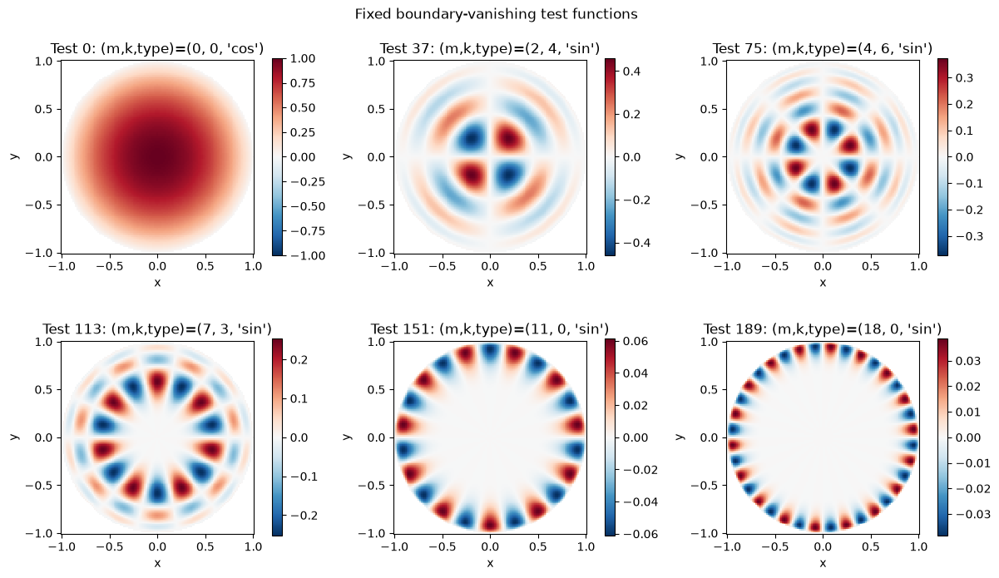

In [10]:
rule=make_test_rule(CONFIG['test_degree'],CONFIG['n_radial'],CONFIG['n_angular'],FORCING)
print('스칼라 시험함수:',len(rule.modes),'| 잔차 성분:',2*len(rule.modes),'| 적분점:',len(rule.xy))
print('적분 가중치 합:',rule.weights.sum(),'| H1 Gram 조건수:',rule.condition)
assert abs(rule.weights.sum()-np.pi)<1e-12
axis=np.linspace(-1,1,121);tx,ty=np.meshgrid(axis,axis);inside=tx*tx+ty*ty<=1
txy=np.column_stack((tx[inside],ty[inside]));values,_,_,modes=disk_tests(txy,CONFIG['test_degree'])
indices=np.linspace(0,len(modes)-1,6,dtype=int)
fig,axes=plt.subplots(2,3,figsize=(12,7),layout='constrained')
for ax,index in zip(axes.ravel(),indices):
    z=np.full(tx.shape,np.nan);z[inside]=values[:,index];limit=max(np.nanmax(np.abs(z)),1e-12)
    im=ax.pcolormesh(tx,ty,z,shading='auto',cmap='RdBu_r',vmin=-limit,vmax=limit)
    ax.set(title=f'Test {index}: (m,k,type)={modes[index]}',xlabel='x',ylabel='y',aspect='equal')
    fig.colorbar(im,ax=ax,shrink=.8)
fig.suptitle('Fixed boundary-vanishing test functions')
display(fig);plt.close(fig)

## 11. 두 방정식의 약형 잔차와 학습 손실

확산항만 부분적분하면 첫 성분의 잔차는
$$
R_i^u=\varepsilon\int\nabla u_\theta\cdot\nabla\psi_i
+\int(u_\theta u_{\theta,x}+v_\theta u_{\theta,y})\psi_i-\int f_1\psi_i
$$
이며 두 번째 성분은 u의 도함수를 v의 도함수로 바꾸어 계산합니다. 시험함수가 경계에서 0이므로 확산 경계항이 사라집니다. 대류항은 원래 형태로 유지합니다. div(u,v)=0이 없으므로 대류를 보존형으로 바꾸면서 발산 보정항을 생략하면 다른 방정식이 됩니다.

학습에는 1차 공간 미분만 필요합니다. 손실은 $L=(R^u)^TG^{-1}R^u+(R^v)^TG^{-1}R^v$이고, 코드에서는 L⁻¹R의 제곱합으로 계산합니다(여기서 L은 Cholesky 인자). `create_graph=True`로 도함수에서 신경망 매개변수까지 역전파합니다. 시험함수와 적분점은 학습 내내 고정합니다.

In [11]:
def first_derivatives(model,points,training=True):
    xy=points.detach().requires_grad_(True)
    uv=model(xy)
    du=torch.autograd.grad(uv[:,0].sum(),xy,create_graph=training,retain_graph=True)[0]
    dv=torch.autograd.grad(uv[:,1].sum(),xy,create_graph=training,retain_graph=training)[0]
    return uv,du,dv


def weak_residual(model,rule,epsilon,training=True):
    uv,du,dv=first_derivatives(model,rule.xy,training)
    grad_x=torch.stack((du[:,0],dv[:,0]),dim=1)
    grad_y=torch.stack((du[:,1],dv[:,1]),dim=1)
    convection=uv[:,0:1]*grad_x+uv[:,1:2]*grad_y
    return epsilon*(rule.Wdx@grad_x+rule.Wdy@grad_y)+rule.Wpsi@convection-rule.load


def weak_loss(residual,rule):
    """두 잔차 성분의 이산 H1 쌍대 노름 제곱. 역행렬은 만들지 않습니다."""
    whitened=torch.linalg.solve_triangular(rule.chol,residual,upper=False)
    return whitened.square().sum()

## 12. 예측과 독립 강형 잔차 평가

아래 강형 잔차는 자동미분으로 두 성분의 2차 공간 미분을 계산하지만 **학습에는 사용하지 않습니다**. 학습용 시험공간 밖의 오차나 경계층 부근의 국소적인 PDE 위반을 찾기 위한 진단입니다. 내부 평가점은 면적에 대해 균일하게 독립 추출하며 원주점은 별도로 생성합니다.

발산 $u_x+v_y$도 함께 계산합니다. vector Burgers에서는 이 값이 0일 필요가 없으므로 발산은 오차가 아닌 참고 지표로 표시합니다. 일반 예측에서는 기울기를 끄지만 공간 미분이 필요한 잔차 계산은 `no_grad` 안에 넣지 않습니다. 메모리 사용량을 제한하기 위해 배치 단위로 평가합니다.

In [12]:
def sample_disk(rng,count):
    r=np.sqrt(rng.random(count));angle=2*np.pi*rng.random(count)
    return np.column_stack((r*np.cos(angle),r*np.sin(angle)))


def circle_points(count):
    t=2*np.pi*np.arange(count)/count
    return np.column_stack((np.cos(t),np.sin(t)))


def predict(model,xy,batch=4096):
    out=[]
    with torch.no_grad():
        for i in range(0,len(xy),batch):
            out.append(model(torch.as_tensor(xy[i:i+batch],dtype=torch.float64)).numpy())
    return np.concatenate(out)


def strong_residual(model,points,epsilon,forcing):
    """독립 진단용입니다. 학습 손실에는 이 함수의 결과를 사용하지 않습니다."""
    xy=points.detach().requires_grad_(True);uv=model(xy)
    gradients=[];laplacians=[]
    for k in range(2):
        grad=torch.autograd.grad(uv[:,k].sum(),xy,create_graph=True,retain_graph=True)[0]
        xx=torch.autograd.grad(grad[:,0].sum(),xy,retain_graph=True)[0][:,0]
        yy=torch.autograd.grad(grad[:,1].sum(),xy,retain_graph=True)[0][:,1]
        gradients.append(grad);laplacians.append(xx+yy)
    du,dv=gradients
    adv=torch.stack((uv[:,0]*du[:,0]+uv[:,1]*du[:,1],uv[:,0]*dv[:,0]+uv[:,1]*dv[:,1]),dim=1)
    residual=adv-epsilon*torch.stack(laplacians,dim=1)-source_tensor(xy,forcing)
    return residual,du[:,0]+dv[:,1]


def independent_residual(model,xy,epsilon,forcing,batch=2048):
    rs=[];div=[]
    for i in range(0,len(xy),batch):
        r,d=strong_residual(model,torch.as_tensor(xy[i:i+batch],dtype=torch.float64),epsilon,forcing)
        rs.append(r.detach().numpy());div.append(d.detach().numpy())
    return np.concatenate(rs),np.concatenate(div)

## 13. 공간 의존 우변과 서로 다른 두 성분 검증

먼저 y=-0.5,0,0.5에서 두 번째 우변이 각각 1,0,-1인지 확인합니다. 다음으로 w=1−x²−y², u=w, v=2w라는 제조해를 사용하여 두 성분의 대류 결합과 미분 부호를 검증합니다. 이 제조해의 우변은 $f_1=4\varepsilon-2w(x+2y)$, $f_2=2f_1$이며 실제 학습 문제와 구분합니다.

제조해 우변에서는 강형·약형 잔차가 0인지 확인하고, 실제 우변 (-1,-sin(pi*y))에서는 약형 잔차가 강형 잔차를 시험함수에 곱해 적분한 값과 같은지 검사합니다. 이는 공간 의존 하중, 부분적분 부호, 벡터 결합, 적분 가중치를 함께 확인하는 과정입니다. 실제 문제의 우변을 제조해로 바꾸는 단계는 아닙니다.

In [13]:
forcing_check=torch.tensor([[.1,-.5],[0.,0.],[.1,.5]],dtype=torch.float64)
torch.testing.assert_close(source_tensor(forcing_check,FORCING),
    torch.tensor([[-1.,1.],[-1.,0.],[-1.,-1.]],dtype=torch.float64))
class UnequalPolynomialCheck(nn.Module):
    def forward(self,xy):
        w=1-xy.square().sum(dim=1,keepdim=True)
        return torch.cat((w,2*w),dim=1)
def manufactured_source(xy):
    w=1-xy.square().sum(dim=1,keepdim=True)
    f=4*EPSILON-2*(xy[:,0:1]+2*xy[:,1:2])*w
    return torch.cat((f,2*f),dim=1)
check_rule=make_test_rule(8,20,64,manufactured_source)
check=weak_residual(UnequalPolynomialCheck(),check_rule,EPSILON,False)
assert float(check.detach().abs().max())<2e-11
points=torch.tensor([[.2,.3],[-.4,.1]],dtype=torch.float64)
strong,_=strong_residual(UnequalPolynomialCheck(),points,EPSILON,manufactured_source)
torch.testing.assert_close(strong,torch.zeros_like(strong),atol=1e-12,rtol=0)
forcing_rule=make_test_rule(8,20,64,FORCING)
weak=weak_residual(UnequalPolynomialCheck(),forcing_rule,EPSILON,False)
strong,_=strong_residual(UnequalPolynomialCheck(),forcing_rule.xy,EPSILON,FORCING)
torch.testing.assert_close(weak,forcing_rule.Wpsi@strong,atol=2e-11,rtol=1e-10)
print('서로 다른 u,v 제조해, 강형-약형 적분 일치 검증 통과')

서로 다른 u,v 제조해, 강형-약형 적분 일치 검증 통과


## 14. Adam과 L-BFGS 학습 함수

각 단계는 신경망의 두 값과 1차 공간 미분을 평가하고, 고정 시험함수에 대한 적분 잔차를 만든 뒤 Gram 쌍대 노름을 최소화합니다. FEM 값, 점별 강형 잔차, u=v 조건은 손실에 포함하지 않습니다. Adam 갱신과 L-BFGS 클로저 호출 횟수는 다른 작업 단위이므로 구분하여 기록합니다.

L-BFGS의 선 탐색에서 목적함수가 변하지 않도록 시험함수와 적분점은 고정합니다. 종료 허용오차를 만족하거나 반복 한도에 도달해도 정확한 PDE 해라는 보장은 없습니다. 따라서 학습 이후 독립 적분, 풍부한 시험공간, 강형 잔차, P3 해 비교를 모두 수행합니다.

In [14]:
def train_vpinn(model,rule,config):
    history=[];start=time.perf_counter()
    opt=torch.optim.Adam(model.parameters(),lr=config['adam_lr'])
    for step in range(1,config['adam_steps']+1):
        opt.zero_grad(set_to_none=True)
        loss=weak_loss(weak_residual(model,rule,config['epsilon']),rule)
        if not torch.isfinite(loss): raise FloatingPointError('유한하지 않은 약형 손실')
        loss.backward();opt.step()
        if step==1 or step%100==0 or step==config['adam_steps']:
            history.append(('Adam',step,float(loss.detach()),time.perf_counter()-start))
            print(f'Adam {step}: 약형 손실={float(loss.detach()):.4e}',flush=True)
    adam_seconds=time.perf_counter()-start;closures=0;iterations=0
    lbfgs_start=time.perf_counter()
    if config['lbfgs_steps']:
        opt=torch.optim.LBFGS(model.parameters(),lr=config['lbfgs_lr'],max_iter=config['lbfgs_steps'],
            max_eval=2*config['lbfgs_steps'],history_size=50,tolerance_grad=1e-10,
            tolerance_change=1e-13,line_search_fn='strong_wolfe')
        def closure():
            nonlocal closures
            opt.zero_grad(set_to_none=True)
            loss=weak_loss(weak_residual(model,rule,config['epsilon']),rule)
            if not torch.isfinite(loss): raise FloatingPointError('유한하지 않은 약형 손실')
            loss.backward();closures+=1
            if closures==1 or closures%100==0:
                history.append(('LBFGS_closure',closures,float(loss.detach()),time.perf_counter()-start))
                print(f'L-BFGS closure {closures}: 약형 손실={float(loss.detach()):.4e}',flush=True)
            return loss
        opt.step(closure)
        iterations=int(opt.state[next(iter(model.parameters()))].get('n_iter',0))
    lbfgs_seconds=time.perf_counter()-lbfgs_start
    final=float(weak_loss(weak_residual(model,rule,config['epsilon'],False),rule).detach())
    history.append(('final',iterations,final,time.perf_counter()-start))
    return history,{'adam_seconds':adam_seconds,'lbfgs_seconds':lbfgs_seconds,
        'train_seconds':time.perf_counter()-start,'adam_updates':config['adam_steps'],
        'lbfgs_iterations':iterations,'lbfgs_closures':closures,'final_weak_loss':final}

## 15. 기본 Gauss VPINN 결과 불러오기

기본 규칙은 제곱 반지름의 Gauss–Legendre 40점 × 등간격 각도 128점, 총 5,120점입니다. seed 2026의 저장 모델을 대표 실행으로 사용하며 최적화 예산은 Adam 3,000회와 L-BFGS 최대 1,500회였습니다. 아래 셀은 재학습하지 않고 모델과 학습 이력을 불러옵니다.

16–30절의 모든 검증과 그림은 이 Gauss 모델에 대응합니다. 5개 시드 평균과 랜덤 배치 세 가지의 비교는 31절 이후에서 확인합니다. 단일 대표 실행과 5개 시드 평균을 구분하십시오.

In [15]:
import study
selected=study.run_path(5120, 'gauss', 2026)
from reference_core import load_checkpoint
model, CONFIG=load_checkpoint(selected/'model.pt')
rule=make_test_rule(CONFIG['test_degree'],40,128,CONFIG['forcing'])
statistics=json.loads((selected/'statistics.json').read_text())
history=list(csv.reader((selected/'history.csv').open(encoding='utf-8-sig')))[1:]
history=[(a,int(b),float(c),float(d)) for a,b,c,d in history]
RUN_DIR=WORK_DIR/'representative_gauss'
print('기본 Gauss 대표 실행:',selected)
print(json.dumps(statistics,indent=2))

기본 Gauss 대표 실행: <local-project>\VPINN_sampling_study_20261118\runs\gauss_N5120_seed2026
{
  "adam_seconds": 93.53426139999647,
  "lbfgs_seconds": 55.62788329995237,
  "train_seconds": 149.17081659997348,
  "adam_updates": 3000,
  "lbfgs_iterations": 1500,
  "lbfgs_closures": 1592,
  "final_weak_loss": 1.370391696780702e-06
}


## 16. 독립 검증과 저장 함수

검증은 세 가지 약형 값을 구분합니다. 첫째는 원래 학습 공간의 잔차, 둘째는 같은 시험함수에 더 촘촘한 적분을 사용한 잔차, 셋째는 더 많은 시험함수에 대한 잔차입니다. 앞의 두 값의 차이는 적분 오차를, 세 번째 값은 제한된 시험공간에서 보이지 않던 성분을 살펴보는 데 사용합니다. 신경망이 비다항식이므로 적분 차수를 높인 검증이 필요합니다.

별도의 내부점 10,000개에서 강형 벡터 잔차를 평가하고, P3 요소별 적분점에서 벡터 및 성분별 L2·표본 L∞ 오차를 계산합니다. 저장 파일에는 모델, 설정, 학습 이력, 수치 지표, 전체 평가 배열이 포함됩니다. 체크포인트는 추론용이며 최적화 중간 상태를 재개하는 파일은 아닙니다.

In [16]:
def validation_diagnostics(model,rule,config,reference):
    epsilon=config['epsilon'];forcing=config['forcing']
    finer=make_test_rule(rule.degree,config['validation_radial'],config['validation_angular'],forcing)
    enriched=make_test_rule(config['validation_degree'],config['validation_radial'],config['validation_angular'],forcing)
    r0=weak_residual(model,rule,epsilon,False).detach()
    r1=weak_residual(model,finer,epsilon,False).detach()
    r2=weak_residual(model,enriched,epsilon,False).detach()
    rng=np.random.default_rng(314159)
    xy=sample_disk(rng,config['eval_points']);uv=predict(model,xy)
    residual,divergence=independent_residual(model,xy,epsilon,forcing)
    boundary_xy=circle_points(1024);boundary=predict(model,boundary_xy)
    qxy,qref,w=reference.quadrature(6);qpred=predict(model,qxy)
    metrics={'weak_training_loss_recomputed':float(weak_loss(r0,rule)),
        'weak_same_tests_finer_quadrature_loss':float(weak_loss(r1,finer)),
        'weak_enriched_tests_loss':float(weak_loss(r2,enriched)),
        'weak_quadrature_difference_norm':float(torch.sqrt(weak_loss(r1-r0,rule))),
        'strong_residual_vector_rms':float(np.sqrt(np.mean(np.sum(residual**2,axis=1)))),
        'strong_residual_vector_sampled_max':float(np.linalg.norm(residual,axis=1).max()),
        'strong_residual_component_rms':np.sqrt(np.mean(residual**2,axis=0)).tolist(),
        'boundary_vector_sampled_max':float(np.linalg.norm(boundary,axis=1).max()),
        'component_difference_rms_diagnostic_only':float(np.sqrt(np.mean((uv[:,0]-uv[:,1])**2))),
        'divergence_rms_diagnostic_only':float(np.sqrt(np.mean(divergence**2))),
        'errors':vector_errors(qpred,qref,w),'comparison_points':len(w),
        'reference_file':reference.path,'reference_polygon_area':reference.area,
        'component_sampled_min':uv.min(axis=0).tolist(),'component_sampled_max':uv.max(axis=0).tolist()}
    data={'xy':xy,'uv':uv,'residual':residual,'divergence':divergence,'boundary_xy':boundary_xy,
          'boundary':boundary,'qxy':qxy,'qref':qref,'qpred':qpred,'weights':w,
          'weak_r_training':r0.numpy(),'weak_r_finer_quad':r1.numpy(),'weak_r_enriched':r2.numpy()}
    return metrics,data


def save_run(output,model,config,history,statistics,metrics,data):
    output=Path(output);output.mkdir(parents=True,exist_ok=True)
    config={**config,'problem_id':'steady_vector_burgers_2d','method':'VPINN',
        'training_objective':'weak residual only; fixed test space; H1 Gram dual norm',
        'reference_used_as_training_labels':False,'torch_version':str(torch.__version__)}
    (output/'config.json').write_text(json.dumps(config,indent=2,ensure_ascii=False))
    (output/'metrics.json').write_text(json.dumps({**statistics,**metrics},indent=2,ensure_ascii=False,allow_nan=False))
    torch.save({'state_dict':model.state_dict(),'config':config},output/'model.pt')
    np.savez_compressed(output/'evaluation.npz',**data)
    with (output/'history.csv').open('w',newline='',encoding='utf-8-sig') as f:
        writer=csv.writer(f);writer.writerow(['phase','step_or_closure','weak_loss','seconds']);writer.writerows(history)
    with (output/'errors.csv').open('w',newline='',encoding='utf-8-sig') as f:
        writer=csv.writer(f);writer.writerow(['성분','상대_L2','표본_상대_Linf','절대_L2','표본_절대_Linf'])
        for key,e in metrics['errors'].items():
            writer.writerow([key,e['relative_l2'],e['sampled_relative_linf'],e['absolute_l2'],e['sampled_absolute_linf']])


def load_checkpoint(path):
    checkpoint=torch.load(path,map_location='cpu',weights_only=True)
    c=checkpoint['config']
    if c.get('problem_id')!='steady_vector_burgers_2d' or c.get('method')!='VPINN':
        raise ValueError('vector Burgers VPINN 체크포인트가 아닙니다.')
    model=VectorDiskNet(c['width'],c['depth']).double()
    model.load_state_dict(checkpoint['state_dict']);model.eval()
    return model,c

## 17. 독립 검증 실행과 결과 저장

학습된 신경망을 현재 우변으로 계산한 미세 P3 참조해와 비교합니다. FEM은 학습 label로 사용하지 않았습니다. 벡터 상대 오차는 두 성분의 유클리드 길이를 기준으로 계산하고 u,v 각각의 오차도 저장합니다. 경계 오차와 강형 잔차는 별도의 평가점에서 구합니다.

u−v의 RMS는 서로 다른 두 물리 성분의 차이이며 오차가 아닙니다. 발산 RMS도 비압축성 위반 점수가 아닙니다. 실제 정확도 지표는 P3 대비 상대 L2·표본 L∞, 독립 PDE 잔차, 경계 오차입니다. `evaluation.npz`에는 약형 잔차 벡터, 강형 잔차, P3 비교 데이터가 저장됩니다.

In [17]:
metrics,evaluation=validation_diagnostics(model,rule,CONFIG,reference)
save_run(RUN_DIR,model,CONFIG,history,statistics,metrics,evaluation)
display(Markdown(
    f"**벡터 상대 L2:** {100*metrics['errors']['vector']['relative_l2']:.5f}%  \n"
    f"**벡터 표본 상대 Linf:** {100*metrics['errors']['vector']['sampled_relative_linf']:.5f}%  \n"
    f"**독립 강형 벡터 잔차 RMS:** {metrics['strong_residual_vector_rms']:.5g}  \n"
    f"**경계 벡터 오차 최대값:** {metrics['boundary_vector_sampled_max']:.3e}  \n"
    f"**RMS(u-v), 성분 차이 (오차 아님):** {metrics['component_difference_rms_diagnostic_only']:.3e}"))
print('약형 검증:',{k:v for k,v in metrics.items() if k.startswith('weak_')})
print('저장 폴더:',RUN_DIR)

약형 검증: {'weak_training_loss_recomputed': 1.3703916967807018e-06, 'weak_same_tests_finer_quadrature_loss': 1.3703916967817938e-06, 'weak_enriched_tests_loss': 1.38488272894601e-06, 'weak_quadrature_difference_norm': 9.649135732628844e-15}
저장 폴더: <local-project>\VPINN_sampling_study_20261118\vector_vpinn_sine_outputs\representative_gauss


**벡터 상대 L2:** 0.04937%  
**벡터 표본 상대 Linf:** 0.07917%  
**독립 강형 벡터 잔차 RMS:** 0.020567  
**경계 벡터 오차 최대값:** 8.384e-16  
**RMS(u-v), 성분 차이 (오차 아님):** 7.738e-01

## 18. 저장 모델 다시 불러오기

시각화 전에 체크포인트를 다시 읽고 독립 평가점의 예측을 저장값과 비교합니다. 이 과정을 통해 메모리에 남아 있는 학습 모델 없이도 결과를 재현할 수 있는지 확인합니다. 모델 파일에는 vector Burgers와 VPINN이라는 식별 정보가 있어 다른 문제의 체크포인트를 섞는 것을 막습니다.

그림은 다시 불러온 모델과 저장한 평가 데이터로 만듭니다. 이후 분석에서 재학습할 필요는 없습니다. `weights_only=True`로 필요한 가중치와 설정만 읽으며, 신경망 구조는 설정에 기록된 너비와 깊이로 복원합니다.

In [18]:
reloaded,reloaded_config=load_checkpoint(RUN_DIR/'model.pt')
np.testing.assert_allclose(predict(reloaded,evaluation['xy']),evaluation['uv'],rtol=1e-12,atol=1e-13)
model=reloaded
print('저장된 모델의 독립 예측값 재현 확인')

저장된 모델의 독립 예측값 재현 확인


## 19. 시각화 격자와 공통 그림 함수

평면 지도는 단위원의 직교 격자에서 계산합니다. 3차원 곡면은 FEM 다각형을 따르는 극좌표 격자를 사용하여 두 해를 동일한 영역에서 비교합니다. FEM 다각형 밖의 참조값은 NaN이며 외삽하지 않습니다. 격자는 표시용이므로 해상도를 바꿔도 P3 적분점으로 계산한 오차 지표는 변하지 않습니다.

표시용 격자의 강형 잔차는 독립 균일 표본의 잔차와 별도로 계산합니다. 최대값이 다를 수 있는 이유는 점 집합이 다르기 때문입니다. 아래의 공통 함수는 축·색 범위·원 경계 표시를 일관되게 처리합니다. 그림 제목은 폰트 호환성을 위해 영문이며 설명은 한글입니다.

In [19]:
def prepare_plot_data(model,reference,config,evaluation,grid_size=201):
    axis=np.linspace(-1,1,grid_size);x,y=np.meshgrid(axis,axis)
    xy=np.column_stack((x.ravel(),y.ravel()));inside=np.sum(xy**2,axis=1)<=1
    uv=np.full((len(xy),2),np.nan);uv[inside]=predict(model,xy[inside])
    ref=reference.evaluate(xy);ref[~inside]=np.nan
    residual=np.full_like(uv,np.nan);div=np.full(len(xy),np.nan)
    residual[inside],div[inside]=independent_residual(model,xy[inside],config['epsilon'],config['forcing'])
    angle=np.linspace(0,2*np.pi,241);directions=np.column_stack((np.cos(angle),np.sin(angle)))
    hull=ConvexHull(reference.p[np.unique(reference.t[:,:3])]);den=hull.equations[:,:2]@directions.T
    intersections=np.full_like(den,np.inf)
    np.divide(-hull.equations[:,2,None],den,out=intersections,where=den>1e-14)
    radius=np.linspace(0,1,101)[:,None]*np.min(intersections,axis=0)[None,:]*(1-1e-12)
    sx,sy=radius*directions[:,0],radius*directions[:,1]
    sxy=np.column_stack((sx.ravel(),sy.ravel()));sp=predict(model,sxy).reshape(*sx.shape,2)
    sr=reference.evaluate(sxy).reshape(*sx.shape,2)
    return SimpleNamespace(model=model,reference=reference,config=config,evaluation=evaluation,
        x=x,y=y,uv=uv.reshape(*x.shape,2),ref=ref.reshape(*x.shape,2),diff=(uv-ref).reshape(*x.shape,2),
        residual=residual.reshape(*x.shape,2),div=div.reshape(x.shape),sx=sx,sy=sy,sp=sp,sr=sr)


def field(fig,ax,d,values,title,cmap='viridis',norm=None):
    image=ax.pcolormesh(d.x,d.y,np.ma.masked_invalid(values),shading='auto',cmap=cmap,norm=norm,rasterized=True)
    theta=np.linspace(0,2*np.pi,361);ax.plot(np.cos(theta),np.sin(theta),lw=.5,color='#4a5568')
    ax.set(xlabel='x',ylabel='y',title=title,aspect='equal',xlim=(-1.02,1.02),ylim=(-1.02,1.02))
    fig.colorbar(image,ax=ax,shrink=.85)

plot_data=prepare_plot_data(model,reference,CONFIG,evaluation,grid_size=201)
figures=[]

## 20. u와 v의 곡면 비교

각 행은 한 성분을 나타냅니다. 왼쪽은 VPINN, 가운데는 P3 FEM, 오른쪽은 절대 오차입니다. 두 해에는 같은 수직축과 색 범위를 사용하여 진폭 차이를 숨기지 않습니다. 절대 오차는 별도의 범위로 표시하며, P3 값은 각 요소의 실제 3차 다항식으로 평가합니다. 원판 전체의 경계조건과 FEM 다각형 경계조건의 차이가 작은 오차에 영향을 줄 수 있습니다.

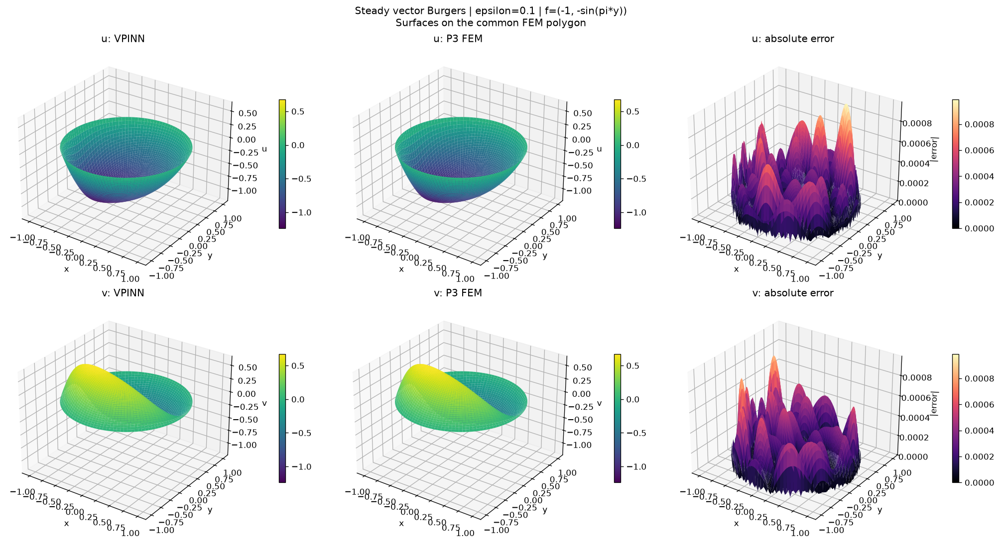

In [20]:
def plot_surfaces(d):
    fig=plt.figure(figsize=(17,9),layout='constrained')
    lo=min(np.nanmin(d.sp),np.nanmin(d.sr));hi=max(np.nanmax(d.sp),np.nanmax(d.sr))
    error_max=max(np.nanmax(np.abs(d.sp-d.sr)),1e-15)
    for k,name in enumerate(('u','v')):
        for j,(label,z) in enumerate((('VPINN',d.sp[:,:,k]),('P3 FEM',d.sr[:,:,k]),('absolute error',np.abs(d.sp[:,:,k]-d.sr[:,:,k])))):
            ax=fig.add_subplot(2,3,3*k+j+1,projection='3d')
            norm=Normalize(lo,hi) if j<2 else Normalize(0,error_max)
            surface=ax.plot_surface(d.sx,d.sy,z,cmap='viridis' if j<2 else 'magma',norm=norm,
                                    rcount=75,ccount=121,linewidth=0,rasterized=True)
            ax.set(xlabel='x',ylabel='y',zlabel=name if j<2 else '|error|',title=f'{name}: {label}')
            ax.set_zlim((lo,hi) if j<2 else (0,error_max));ax.view_init(28,-55)
            fig.colorbar(surface,ax=ax,shrink=.55,pad=.08)
    fig.suptitle(f'Steady vector Burgers | epsilon={d.config["epsilon"]:g} | f=(-1, -sin(pi*y))\nSurfaces on the common FEM polygon')
    return fig

fig=plot_surfaces(plot_data)
figures.append(('01_component_surfaces',fig))
display(fig)
plt.close(fig)

## 21. 성분별 평면 해와 부호 있는 오차

u,v 두 행에 각각 VPINN, P3, 부호 있는 차이를 표시합니다. 오차의 양·음은 참조해보다 크게 또는 작게 예측한 위치를 뜻합니다. 이번에는 두 우변이 다르므로 성분별 해의 모양과 크기도 다를 수 있습니다. 이 그림은 각 출력의 학습 정도와 경계 부근의 오차 구조를 비교하는 데 사용합니다.

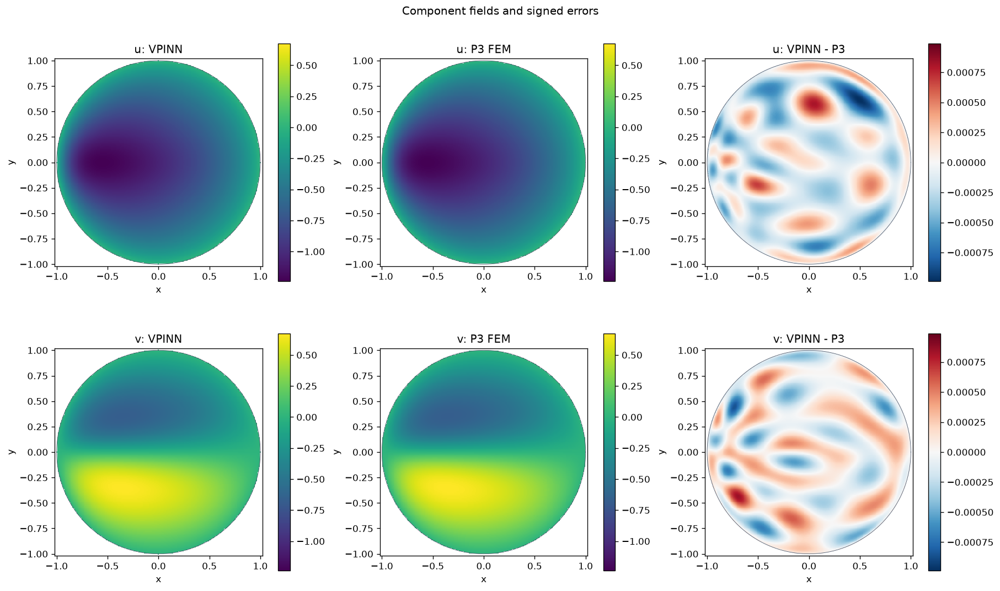

In [21]:
def plot_maps(d):
    fig,ax=plt.subplots(2,3,figsize=(15,9),layout='constrained')
    norm=Normalize(min(np.nanmin(d.uv),np.nanmin(d.ref)),max(np.nanmax(d.uv),np.nanmax(d.ref)))
    e=max(np.nanmax(np.abs(d.diff)),1e-15)
    for k,name in enumerate(('u','v')):
        field(fig,ax[k,0],d,d.uv[:,:,k],f'{name}: VPINN',norm=norm)
        field(fig,ax[k,1],d,d.ref[:,:,k],f'{name}: P3 FEM',norm=norm)
        field(fig,ax[k,2],d,d.diff[:,:,k],f'{name}: VPINN - P3','RdBu_r',Normalize(-e,e))
    fig.suptitle('Component fields and signed errors')
    return fig

fig=plot_maps(plot_data)
figures.append(('02_component_maps',fig))
display(fig)
plt.close(fig)

## 22. 벡터 크기와 방향

벡터 크기는 sqrt(u²+v²)이며 화살표는 (u,v) 방향을 보여 줍니다. 오른쪽은 두 벡터의 차이의 길이입니다. 단순히 두 벡터 크기의 차이를 구하는 것과는 다릅니다. 두 번째 우변은 y=0 위아래에서 부호가 바뀝니다. 벡터의 방향은 학습된 두 성분의 부호와 크기를 함께 반영하므로, 성분별 해와 P3 결과를 함께 확인하십시오. 이는 속도 방향 표시이며 비압축성 유동이라는 의미는 아닙니다.

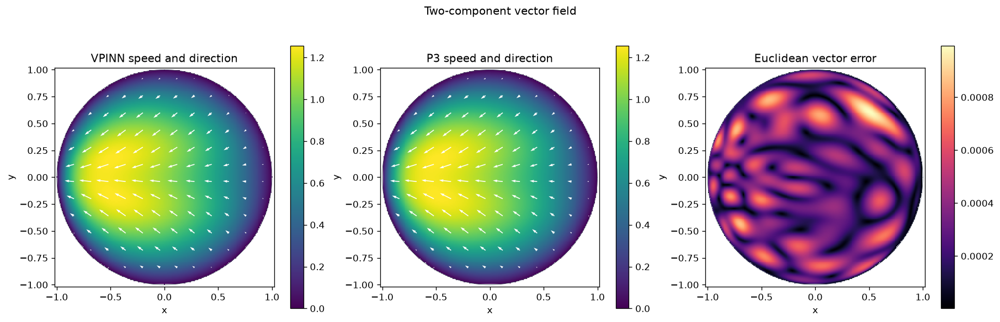

In [22]:
def plot_vector_field(d):
    fig,ax=plt.subplots(1,3,figsize=(15,5),layout='constrained')
    speed=np.linalg.norm(d.uv,axis=2);ref_speed=np.linalg.norm(d.ref,axis=2)
    norm=Normalize(0,max(np.nanmax(speed),np.nanmax(ref_speed)))
    field(fig,ax[0],d,speed,'VPINN speed and direction',norm=norm)
    field(fig,ax[1],d,ref_speed,'P3 speed and direction',norm=norm)
    for a,z in zip(ax[:2],(d.uv,d.ref)):
        a.quiver(d.x[::16,::16],d.y[::16,::16],z[::16,::16,0],z[::16,::16,1],color='white',scale=22,width=.004)
    field(fig,ax[2],d,np.linalg.norm(d.diff,axis=2),'Euclidean vector error','magma')
    fig.suptitle('Two-component vector field')
    return fig

fig=plot_vector_field(plot_data)
figures.append(('03_vector_field',fig))
display(fig)
plt.close(fig)

## 23. 벡터 및 성분별 오차 지표

벡터, u, v 각각의 상대 L2와 표본 상대 L∞를 백분율로 비교합니다. 옆 표는 약형 검증과 강형·경계 진단을 함께 보여 줍니다. 약형 손실과 강형 잔차는 단위와 정의가 다르므로 수치만으로 직접 우열을 비교하지 않습니다. 작은 경계 오차는 함수 형태로 부과한 조건의 결과이며 내부 해의 정확도를 보장하지 않습니다.

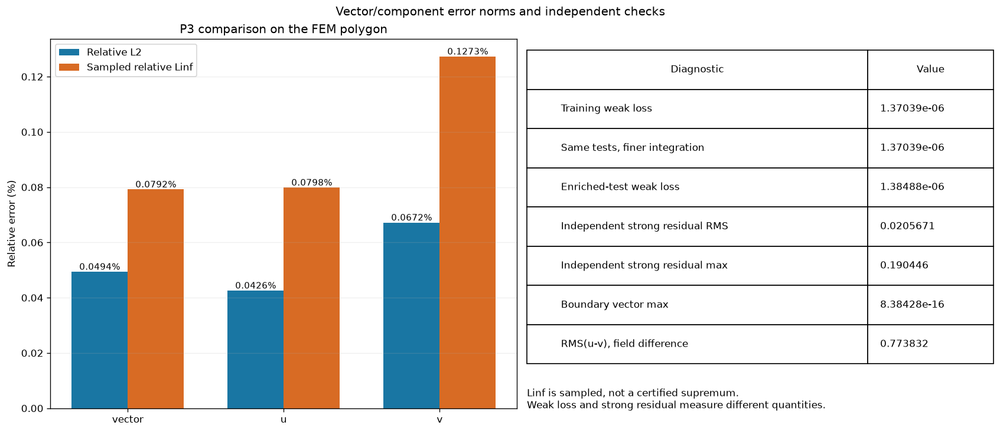

In [23]:
def plot_metrics(metrics):
    fig,ax=plt.subplots(1,2,figsize=(14,6),layout='constrained');keys=('vector','u','v');x=np.arange(3)
    for shift,key,label,color in ((-.18,'relative_l2','Relative L2','#1976a3'),(.18,'sampled_relative_linf','Sampled relative Linf','#d86b24')):
        vals=[100*metrics['errors'][k][key] for k in keys]
        bars=ax[0].bar(x+shift,vals,.36,label=label,color=color);ax[0].bar_label(bars,fmt='%.4f%%',fontsize=9)
    ax[0].set(xticks=x,xticklabels=keys,ylabel='Relative error (%)',title='P3 comparison on the FEM polygon')
    ax[0].legend();ax[0].grid(axis='y',alpha=.2)
    rows=[('Training weak loss',metrics['weak_training_loss_recomputed']),
          ('Same tests, finer integration',metrics['weak_same_tests_finer_quadrature_loss']),
          ('Enriched-test weak loss',metrics['weak_enriched_tests_loss']),
          ('Independent strong residual RMS',metrics['strong_residual_vector_rms']),
          ('Independent strong residual max',metrics['strong_residual_vector_sampled_max']),
          ('Boundary vector max',metrics['boundary_vector_sampled_max']),
          ('RMS(u-v), field difference',metrics['component_difference_rms_diagnostic_only'])]
    ax[1].axis('off');table=ax[1].table(cellText=[[k,f'{v:.6g}'] for k,v in rows],
        colLabels=['Diagnostic','Value'],cellLoc='left',colWidths=[.73,.27],bbox=[0,.12,1,.85])
    table.auto_set_font_size(False);table.set_fontsize(10)
    ax[1].text(0,0,'Linf is sampled, not a certified supremum.\nWeak loss and strong residual measure different quantities.',fontsize=10)
    fig.suptitle('Vector/component error norms and independent checks')
    return fig

fig=plot_metrics(metrics)
figures.append(('04_error_metrics',fig))
display(fig)
plt.close(fig)

## 24. 수평·수직 단면

y=-0.5,0,0.5의 수평 단면과 x=-0.5,0,0.5의 수직 단면에서 두 성분을 비교합니다. 실선은 VPINN, 점선은 P3이며 겹치는 정도로 공간 분포를 확인합니다. 참조 메시 바깥에서는 곡선을 끊고 외삽하지 않습니다. 단면 배열은 이후 CSV로 저장하여 다른 프로그램에서도 비교할 수 있습니다.

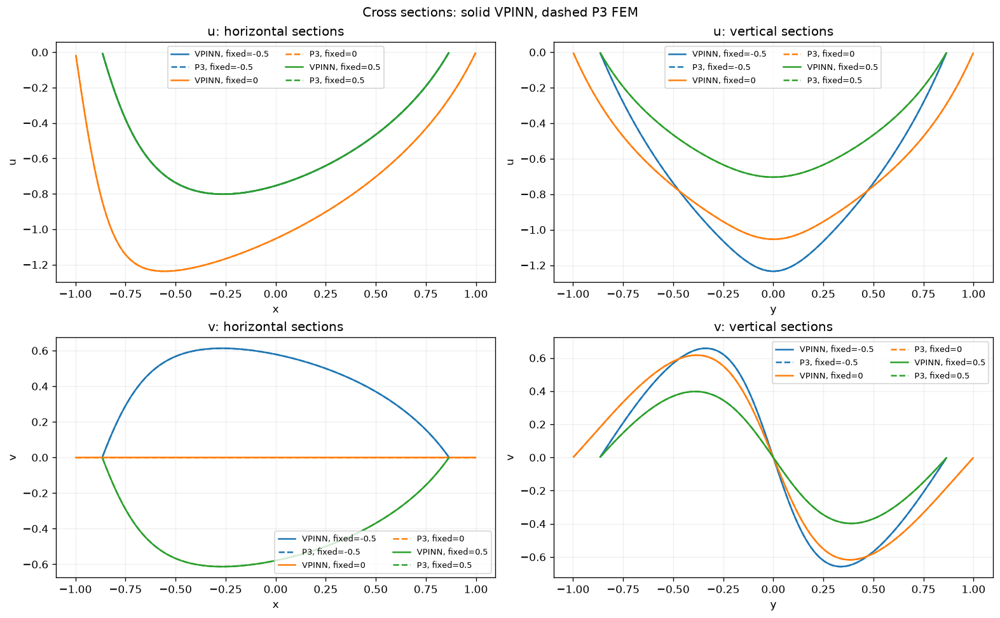

In [24]:
def plot_sections(d):
    fig,ax=plt.subplots(2,2,figsize=(13,8),layout='constrained');rows=[]
    for k,name in enumerate(('u','v')):
        for col,direction in enumerate(('x','y')):
            for fixed in (-.5,0,.5):
                extent=np.sqrt(1-fixed*fixed);line=np.linspace(-extent,extent,801)
                xy=np.column_stack((line,np.full_like(line,fixed))) if col==0 else np.column_stack((np.full_like(line,fixed),line))
                p=predict(d.model,xy);r=d.reference.evaluate(xy);valid=np.isfinite(r).all(axis=1)
                p[~valid]=np.nan
                ln=ax[k,col].plot(line,p[:,k],label=f'VPINN, fixed={fixed:g}')[0]
                ax[k,col].plot(line,r[:,k],'--',color=ln.get_color(),label=f'P3, fixed={fixed:g}')
                if k==0:
                    rows.extend((direction,fixed,*point,*pred,*ref) for point,pred,ref in zip(xy,p,r))
            ax[k,col].set(xlabel=direction,ylabel=name,title=f'{name}: '+('horizontal sections' if col==0 else 'vertical sections'))
            ax[k,col].legend(fontsize=8,ncol=2);ax[k,col].grid(alpha=.2)
    fig.suptitle('Cross sections: solid VPINN, dashed P3 FEM')
    return fig,rows

fig,section_rows=plot_sections(plot_data)
figures.append(('05_cross_sections',fig))
display(fig)
plt.close(fig)

## 25. 독립 강형 잔차와 경계 검증

각 성분의 강형 잔차 절댓값을 표시용 격자에서 그립니다. 아래에는 학습에 쓰지 않은 균일 면적 표본의 벡터 잔차 분포와 원주 경계 오차를 표시합니다. 이 잔차들은 VPINN 학습 손실에 추가되지 않습니다. 평균 약형 잔차가 작아도 국소적인 강형 잔차가 남을 수 있음을 확인하는 그림입니다.

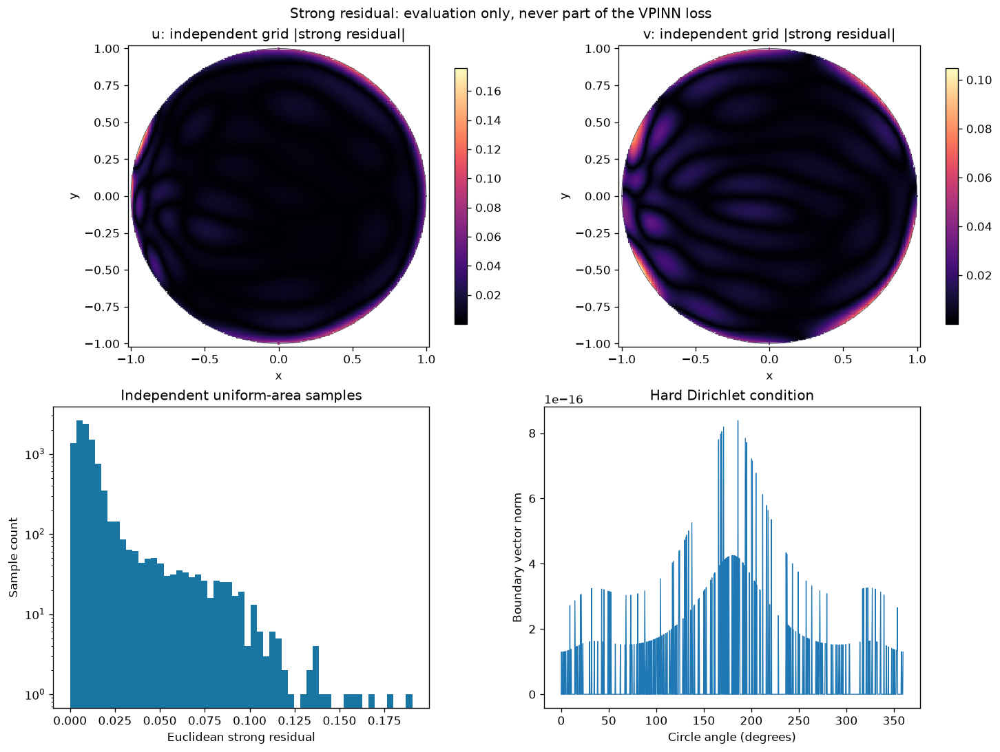

In [25]:
def plot_strong_diagnostics(d):
    fig,ax=plt.subplots(2,2,figsize=(12,9),layout='constrained')
    for k,name in enumerate(('u','v')):
        field(fig,ax[0,k],d,np.abs(d.residual[:,:,k]),f'{name}: independent grid |strong residual|','magma')
    r=np.linalg.norm(d.evaluation['residual'],axis=1)
    ax[1,0].hist(r,bins=55,color='#1976a3');ax[1,0].set(yscale='log',xlabel='Euclidean strong residual',ylabel='Sample count',title='Independent uniform-area samples')
    b=d.evaluation['boundary'];angle=np.arange(len(b))*360/len(b)
    ax[1,1].plot(angle,np.linalg.norm(b,axis=1),lw=.8)
    ax[1,1].set(xlabel='Circle angle (degrees)',ylabel='Boundary vector norm',title='Hard Dirichlet condition')
    fig.suptitle('Strong residual: evaluation only, never part of the VPINN loss')
    return fig

fig=plot_strong_diagnostics(plot_data)
figures.append(('06_strong_diagnostics',fig))
display(fig)
plt.close(fig)

## 26. 약형 학습 이력과 독립 시험공간 검증

시간에 따른 약형 손실, Cholesky 변환된 잔차 성분별 기여, 더 촘촘한 적분 및 더 큰 시험공간의 손실을 구분하여 표시합니다. 변환된 잔차의 각 좌표는 원래 시험함수들의 조합에 해당합니다. 더 큰 시험공간에서 손실이 커지면 기존 시험함수만으로 검사하지 못한 잔차가 있음을 의미하며, 시험공간·학습량을 늘리는 실험의 근거로 삼을 수 있습니다.

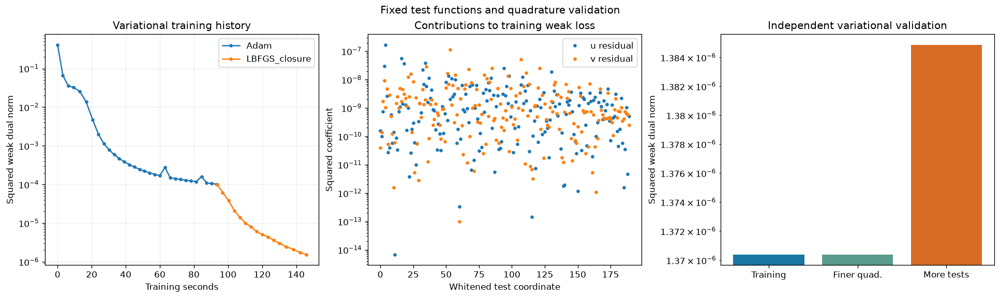

In [26]:
def plot_variational(history,rule,evaluation,metrics):
    fig,ax=plt.subplots(1,3,figsize=(16,4.7),layout='constrained')
    for phase in ('Adam','LBFGS_closure'):
        rows=[r for r in history if r[0]==phase]
        if rows: ax[0].semilogy([r[3] for r in rows],[r[2] for r in rows],'.-',label=phase)
    ax[0].set(xlabel='Training seconds',ylabel='Squared weak dual norm',title='Variational training history');ax[0].legend();ax[0].grid(alpha=.2)
    residual=evaluation['weak_r_training'];z=np.linalg.solve(rule.chol.numpy(),residual)
    for k,label in enumerate(('u residual','v residual')): ax[1].semilogy(np.maximum(z[:,k]**2,1e-30),'.',label=label)
    ax[1].set(xlabel='Whitened test coordinate',ylabel='Squared coefficient',title='Contributions to training weak loss');ax[1].legend()
    vals=[metrics[k] for k in ('weak_training_loss_recomputed','weak_same_tests_finer_quadrature_loss','weak_enriched_tests_loss')]
    ax[2].bar(['Training','Finer quad.','More tests'],np.maximum(vals,1e-30),color=['#1976a3','#5a9b8e','#d86b24'])
    ax[2].set(yscale='log',ylabel='Squared weak dual norm',title='Independent variational validation')
    fig.suptitle('Fixed test functions and quadrature validation')
    return fig

fig=plot_variational(history,rule,evaluation,metrics)
figures.append(('07_variational_validation',fig))
display(fig)
plt.close(fig)

## 27. 서로 다른 두 성분과 발산 진단

첫 그림은 u−v라는 물리적인 성분 차이를 보여 줍니다. 우변이 다르므로 이 값을 0으로 만들거나 동일성 오차라고 해석하지 않습니다. 마지막 산점도는 동일한 P3 적분점에서 (u,v) 쌍을 VPINN과 FEM으로 비교합니다. u=v 직선에 가까운지를 정확도 기준으로 사용하지 않습니다.

가운데 발산 지도는 vector Burgers 해의 공간 변화를 보여 주는 참고 그림입니다. 발산을 0으로 강제하지 않으며 압력 방정식도 없습니다. 성분별 상대 오차와 벡터 상대 오차는 앞의 P3 비교 표에서 확인합니다.

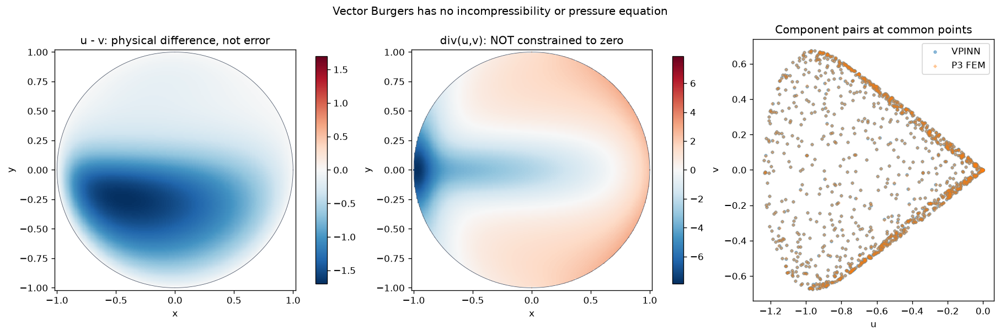

In [27]:
def plot_vector_structure(d):
    fig,ax=plt.subplots(1,3,figsize=(15,5),layout='constrained')
    delta=d.uv[:,:,0]-d.uv[:,:,1];v=max(np.nanmax(np.abs(delta)),1e-15)
    field(fig,ax[0],d,delta,'u - v: physical difference, not error','RdBu_r',Normalize(-v,v))
    divmax=max(np.nanmax(np.abs(d.div)),1e-15)
    field(fig,ax[1],d,d.div,'div(u,v): NOT constrained to zero','RdBu_r',Normalize(-divmax,divmax))
    p=d.evaluation['qpred'][::600];r=d.evaluation['qref'][::600]
    ax[2].scatter(p[:,0],p[:,1],s=8,alpha=.45,label='VPINN')
    ax[2].scatter(r[:,0],r[:,1],s=12,alpha=.45,marker='+',label='P3 FEM')
    ax[2].legend()
    ax[2].set(xlabel='u',ylabel='v',title='Component pairs at common points',aspect='equal')
    fig.suptitle('Vector Burgers has no incompressibility or pressure equation')
    return fig

fig=plot_vector_structure(plot_data)
figures.append(('08_vector_structure',fig))
display(fig)
plt.close(fig)

## 28. FEM 메시와 기록된 계산 비용

P3 메시의 직선 변과 전체 벡터 자유도 수를 표시합니다. P3 고차 자유도는 해 근사의 차수이며 경계가 곡선이라는 뜻은 아닙니다. 비용 그림은 MATLAB의 메시 생성·초기 조립·결합 Newton 풀이와 VPINN의 최적화 시간을 구분합니다. 서로 다른 작업이므로 이 단일 실행 그림을 속도 향상 벤치마크로 해석하지 않습니다.

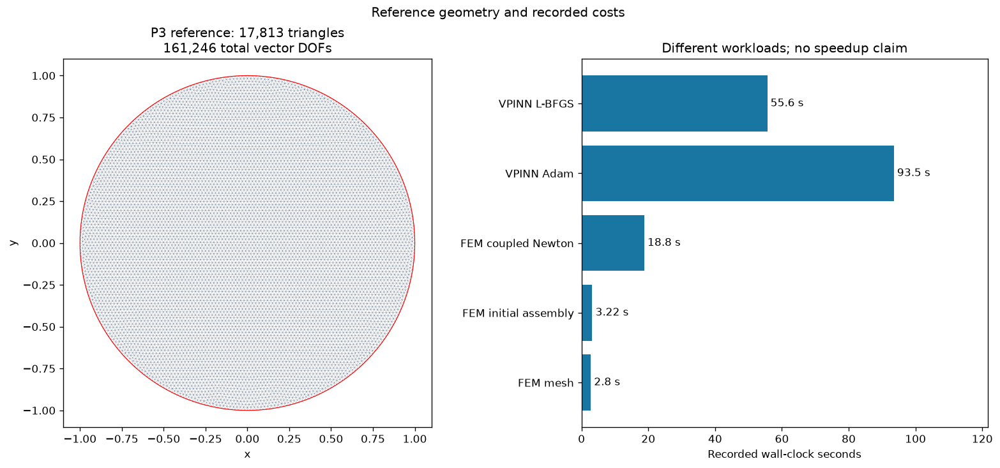

In [28]:
def plot_mesh_cost(reference,statistics):
    fig,ax=plt.subplots(1,2,figsize=(13,6),layout='constrained')
    ids,inv=np.unique(reference.t[:,:3],return_inverse=True)
    tri=Triangulation(reference.p[ids,0],reference.p[ids,1],inv.reshape(-1,3))
    for line in ax[0].triplot(tri,color='#718096',lw=.2): line.set_rasterized(True)
    theta=np.linspace(0,2*np.pi,361);ax[0].plot(np.cos(theta),np.sin(theta),'r-',lw=.7)
    ax[0].set(xlabel='x',ylabel='y',aspect='equal',title=f'P3 reference: {len(reference.t):,} triangles\n{2*len(reference.u):,} total vector DOFs')
    times={**reference.fem_times,**statistics}
    entries=[(label,times[key]) for key,label in [('mesh_seconds','FEM mesh'),('assembly_seconds','FEM initial assembly'),('solve_seconds','FEM coupled Newton'),('adam_seconds','VPINN Adam'),('lbfgs_seconds','VPINN L-BFGS')] if key in times and times[key]>0]
    ax[1].barh([x[0] for x in entries],[x[1] for x in entries],color='#1976a3')
    ax[1].set(xlabel='Recorded wall-clock seconds',title='Different workloads; no speedup claim')
    for label,t in entries: ax[1].text(t,label,f' {t:.3g} s',va='center')
    ax[1].set_xlim(right=max(t for _,t in entries)*1.3)
    fig.suptitle('Reference geometry and recorded costs')
    return fig

fig=plot_mesh_cost(reference,statistics)
figures.append(('09_mesh_and_cost',fig))
display(fig)
plt.close(fig)

## 29. 그림과 시각화 배열 저장

아홉 개의 비교 그림을 PNG로 저장하고 하나의 다중 페이지 PDF에도 모읍니다. 표시용 격자의 두 성분, P3 값, 오차, 강형 잔차, 발산과 곡면 좌표를 NPZ로 저장합니다. 단면값은 UTF-8 CSV로 내보냅니다. 저장된 학습 체크포인트와 수치 지표는 앞 단계의 파일에 그대로 있습니다.

인라인 표시를 닫아도 목록에 보관한 그림 객체는 남아 있으므로 여기서 다시 학습하거나 계산하지 않고 저장할 수 있습니다. 수치 데이터가 있으므로 다른 그림 스타일로 후처리할 때도 신경망을 다시 학습할 필요가 없습니다.

In [29]:
def save_figures(figures,d,sections,output):
    from matplotlib.backends.backend_pdf import PdfPages
    output=Path(output);output.mkdir(parents=True,exist_ok=True)
    with PdfPages(output/'vector_vpinn_report.pdf') as pdf:
        pdf.infodict()['Title']='Steady vector Burgers VPINN and P3 FEM'
        for name,fig in figures:
            fig.savefig(output/f'{name}.png',dpi=160);pdf.savefig(fig)
    np.savez_compressed(output/'plot_fields.npz',x=d.x,y=d.y,uv_vpinn=d.uv,uv_p3=d.ref,
        error=d.diff,strong_residual=d.residual,divergence=d.div,surface_x=d.sx,surface_y=d.sy,
        surface_vpinn=d.sp,surface_p3=d.sr)
    with (output/'cross_sections.csv').open('w',newline='',encoding='utf-8-sig') as f:
        writer=csv.writer(f);writer.writerow(['변하는_좌표','고정_좌표값','x','y','u_VPINN','v_VPINN','u_P3','v_P3']);writer.writerows(sections)

save_figures(figures,plot_data,section_rows,RUN_DIR/'visualizations')
print('그림 및 배열 저장:',RUN_DIR/'visualizations')

그림 및 배열 저장: <local-project>\VPINN_sampling_study_20261118\vector_vpinn_sine_outputs\representative_gauss\visualizations


## 30. 원본 Python·MATLAB 소스 내보내기

노트북은 모든 계산 함수를 직접 포함하지만, 필요하면 원본 모듈을 파일로 내보낼 수도 있습니다. `vpinn_disk.py`에는 학습과 평가 함수, `p3_vector_reference.py`에는 참조해 판독기, `visualize_results.py`에는 그림 함수가 있습니다. MATLAB 솔버와 패키지 목록도 포함합니다. 기본 실행에 이 파일들이 미리 존재할 필요는 없습니다.

파일은 출력 폴더의 `source_exports/`에 저장합니다. 기존 파일의 내용이 다르면 사용자가 수정했을 수 있으므로 보존합니다. 이 스크립트들은 notebook에서 사용한 함수 모듈이며, 임의의 새 문제를 자동으로 해석하는 범용 솔버는 아닙니다.

In [30]:
EXPORT_SOURCES=True
if EXPORT_SOURCES:
    for name,source in BUNDLE['sources'].items():
        path=WORK_DIR/'source_exports'/name;path.parent.mkdir(parents=True,exist_ok=True)
        if path.exists() and path.read_text(encoding='utf-8')!=source:
            print('기존 수정 파일 보존:',path);continue
        path.write_text(source,encoding='utf-8')
    print('원본 소스:',WORK_DIR/'source_exports')

원본 소스: <local-project>\VPINN_sampling_study_20261118\vector_vpinn_sine_outputs\source_exports


## 결과 해석과 확장 실험

- **방법을 구분하십시오.** 학습은 고정 시험함수의 약형 잔차만 사용하는 VPINN입니다. 강형 점별 잔차는 독립 진단이며, FEM은 사후 참조입니다.
- **공간 의존 우변을 일관되게 사용하십시오.** $f_1=-1$, $f_2=-\sin(\pi y)$를 Python 약형·강형 평가와 MATLAB P3 하중에 모두 적용했습니다. 예전 상수 우변 참조해와 비교하면 안 됩니다. 이번에는 u=v를 기대하지 않으며 u−v는 성분 차이입니다.
- **적분 오차와 시험공간 오차를 구분하십시오.** 같은 시험함수에서 적분점만 늘린 결과와, 시험함수까지 늘린 결과는 서로 다른 정보를 줍니다. 약형 손실 하나만으로 정확도를 판단하지 않습니다.
- **참조해와 형상 오차를 고려하십시오.** 상대 L2·표본 L∞는 FEM 다각형에서 계산합니다. 작은 차이가 연속 PDE 정확해에 대한 오차를 인증하지는 않습니다.
- **압력과 비압축성 조건은 없습니다.** div(u,v)가 0이 아닌 것은 이 방정식에서 자연스러울 수 있습니다. 작은 epsilon에서의 층 해상도와 안정성은 별도 실험이 필요합니다.

약형 신경망의 배경은 [Kharazmi 등의 hp-VPINN 논문](https://arxiv.org/abs/2003.05385)과 [시험함수·수치적분의 역할에 관한 논문](https://arxiv.org/abs/2109.02035)을 참고할 수 있습니다. 여기서 사용한 원판 다항식 시험공간, H1 Gram 정규화, 벡터 Burgers 구성은 이 실습에 맞춘 구현입니다.

## 31. 확장 비교 실험: Gauss 기준과 랜덤 적분점 배치

점 개수 1280/2560/5120, 랜덤 3종(균등/약한/강한 경계 강조) 및 Gauss 3종(기본/약한/강한 경계 강조), 공통 시드 2026–2030의 90회 실험입니다. 원판, PDE, P3 참조해, 네트워크 32×3, 시험 차수 18, Adam 3000 및 L-BFGS 최대 1500회는 동일합니다. 공간 배치만 바꾸며 미니배치 학습은 하지 않습니다. 각 실행의 점은 최적화 동안 고정합니다.

제곱 반지름 s=r²의 밀도는 q(s)=(1−a)+a·5s⁴이며 a=0/0.3/0.7입니다. 랜덤 규칙의 가중치는 π/[Nq(s)]입니다. 균등 성분을 유지하여 내부의 양의 밀도를 보장합니다. 강한 경계 강조는 경계조건 페널티가 아니라 내부 적분점의 분포입니다. 가중치 합을 강제로 π로 정규화하지 않습니다. Gram과 하중도 같은 중요도 가중치로 조립합니다.

같은 시드는 초기 가중치와 샘플링의 공통 난수를 공유합니다. 랜덤 점 개수 간에는 큰 표본의 prefix를 사용합니다. 검증은 모든 실행에 같은 10000개 독립 점, 56×160 Gauss 적분, 차수 18/22 시험공간, 동일 P3 요소별 적분점을 사용합니다. 표준오차는 표본 표준편차(ddof=1)/√5이며 신뢰구간이나 공간 오차가 아닙니다. 시드 변화는 초기화와 점 추출의 변동을 함께 포함합니다.

**Gauss 기준 추가:** 네 번째 조건은 원본의 Gauss–Legendre × 등간격 각도 규칙입니다. 점 개수별로 20×64, 20×128, 40×128을 사용합니다. 동일한 5개 시드의 초기 가중치, 네트워크, 최적화 예산, 독립 검증 및 P3 참조해는 랜덤 조건과 같습니다. Gauss에서는 점과 가중치가 시드에 따라 변하지 않습니다. 따라서 Gauss의 SE는 초기화 변동이며 랜덤 조건의 SE는 초기화와 표본 변동을 함께 포함합니다. Gauss 규칙은 점 개수 사이의 중첩 표본이 아닙니다.

**Gauss 경계 강조 추가:** `gauss_boundary_weak`는 강조 계수 0.3, `gauss_boundary_strong`은 0.7입니다. 기존 기본 Gauss 15회와 랜덤 45회를 보존하고 30회만 새로 학습합니다.

Gauss 점을 놓는 변수는 $t=F(s)=(1-\alpha)s+\alpha s^5$이며 $s=r^2$입니다. [0,1]의 Gauss 점과 가중치를 각각 $t_i,\omega_i$로 두고 $s_i=F^{-1}(t_i)$를 이분법으로 구합니다. 각도는 기존 등간격 규칙을 사용합니다. 실제 면적 적분 가중치는

$$w_{ij}=\frac{\pi\omega_i}{n_\theta q(s_i)},\qquad q(s)=1-\alpha+5\alpha s^4.$$

점은 경계 쪽으로 이동하지만 변수변환 가중치로 같은 면적 적분을 근사합니다. 랜덤 규칙의 가중치와 Gauss 가중치를 혼동하지 마십시오. Gauss 세 조건 모두 적분점과 가중치는 시드에 따라 바뀌지 않습니다. SE는 초기화 변동입니다. 원래 Gauss도 끝점에 점이 몰리므로 균등 랜덤과 같은 배치가 아닙니다. 같은 q를 써도 결정론적 점 개수 비율은 랜덤 기대 비율과 같지 않습니다.

변수변환 후에는 원래 s 다항식의 정확 적분 성질이 보존되지 않을 수 있습니다. 따라서 경계 강조를 정확도 개선으로 단정하지 않고 제조해 적분 오차, 독립 잔차, P3 차이를 모두 확인합니다. 그 외 학습·검증 조건은 동일합니다.


**기본과 비교 실험:** 앞의 기본 해설·그림은 Gauss 5,120점·seed 2026입니다. 여기서부터 균등 랜덤, 약한 경계 강조 랜덤, 강한 경계 강조 랜덤을 비교 대상으로 사용합니다. 경계 강조 Gauss도 별도의 확장 조건입니다. 아래 셀은 기존 결과만 읽으며 `RUN_COMPARISON_EXPERIMENTS=True`일 때만 전체 실험 실행 함수를 호출합니다.

N,distribution,n_seeds,relative_l2_mean,relative_l2_se,strong_rms_mean,strong_rms_se,independent_weak_mean
1280,gauss,5,0.0005878652805596628,3.560554697938035e-05,0.025310999098438768,0.00221180487015802,1.997805737924118e-06
1280,gauss_boundary_weak,5,0.0005821638521867045,4.005127339879295e-05,0.02622992807124679,0.00247014209483578,2.050801892438591e-06
1280,gauss_boundary_strong,5,0.0005728112248443202,4.299921628341312e-05,0.025697044822557535,0.0023797598155001908,2.000005395927621e-06
1280,uniform,5,0.5946193642995344,0.22623388155437138,193.6087388732663,41.18783749894704,0.8397317435674945
1280,boundary_weak,5,0.5900011981451534,0.15968825351609547,85.50952513525864,16.23484121659669,0.51398184485214
1280,boundary_strong,5,0.3833209885549441,0.02539136802520198,43.31606044717128,9.981541734361427,0.3545946825820087
2560,gauss,5,0.000571050280503415,4.322154106211532e-05,0.02588445541415644,0.0021513999804352707,1.978649439470034e-06
2560,gauss_boundary_weak,5,0.0005939924572573983,4.19783472014252e-05,0.02578189301031416,0.0021045597018586053,2.0317664450337703e-06
2560,gauss_boundary_strong,5,0.0005788450389697401,4.061655807553195e-05,0.025243352923189355,0.002067798143967887,1.9595233793992666e-06
2560,uniform,5,0.38167819369456846,0.1343423009864355,119.04034108212446,29.364209570987242,0.25111407612256775


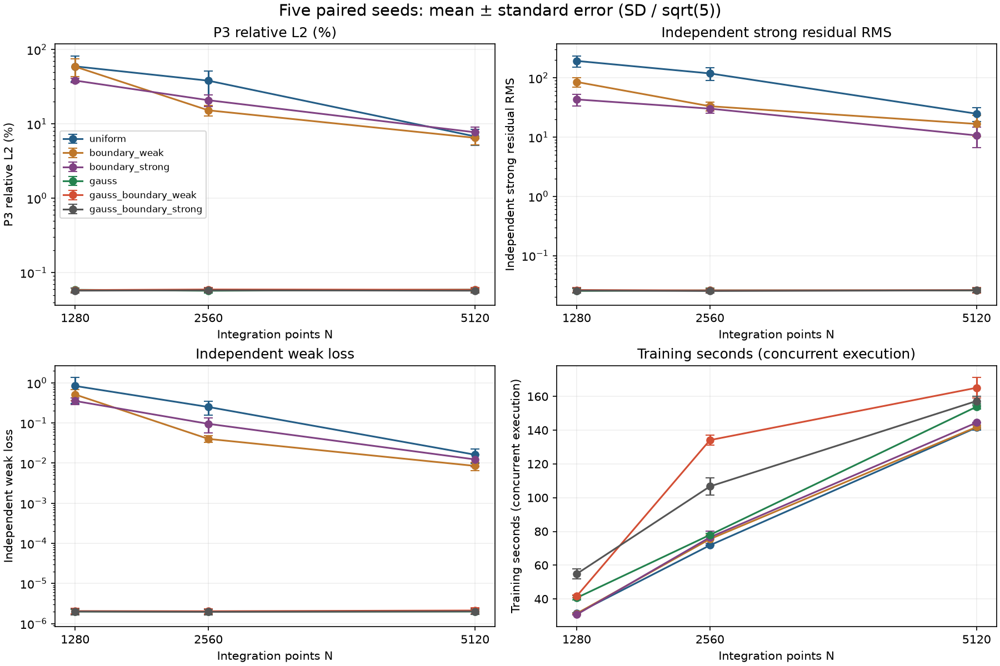

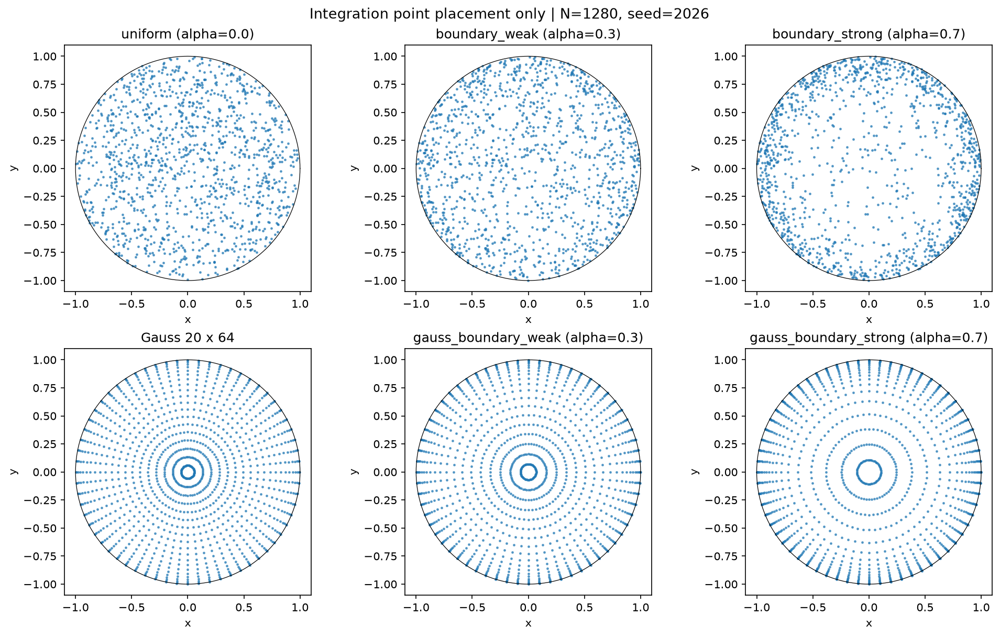

In [31]:
RUN_COMPARISON_EXPERIMENTS=False
if RUN_COMPARISON_EXPERIMENTS:
    study.run_all(workers=3)
summary=list(csv.DictReader(Path('summary.csv').open(encoding='utf-8-sig')))
order={m:i for i,m in enumerate(['gauss','gauss_boundary_weak','gauss_boundary_strong','uniform','boundary_weak','boundary_strong'])}
summary.sort(key=lambda r:(int(r['N']),order[r['distribution']]))
import html
from IPython.display import HTML, Image
columns=['N','distribution','n_seeds','relative_l2_mean','relative_l2_se','strong_rms_mean','strong_rms_se','independent_weak_mean']
rows='<tr>'+''.join('<th>'+html.escape(k)+'</th>' for k in columns)+'</tr>'
for row in summary:
    rows+='<tr>'+''.join('<td>'+html.escape(str(row[k]))+'</td>' for k in columns)+'</tr>'
display(HTML('<p>상대 L2 값은 비율입니다. 백분율은 100을 곱합니다. SE는 표본 표준편차 / √5입니다.</p><table>'+rows+'</table>'))
display(Image(filename='figures/aggregate.png'))
display(Image(filename='figures/points.png'))

## 32. 결과 해석과 재현

평균만으로 순위를 확정하지 말고 표준오차, 개별 시드, 공통 독립 약형 손실, 강형 잔차, FEM 오차를 함께 비교하십시오. 학습 손실이 낮고 독립 손실이 높으면 표본 적분에 대한 과적합을 의심할 수 있습니다. 경계 강조가 항상 유리하지는 않습니다. 기존 완료 실행은 설정과 코드 해시가 일치할 때만 재사용하며, 각 실행에 모델/설정/점/가중치/이력/지표를 보존합니다.

[HTML 해설 열기](index.html) · [개별 결과 CSV](results.csv) · [평균과 표준오차 CSV](summary.csv)

## 33. 평균 해, FEM, 불확실성의 해석

아래 선택값을 바꾸면 완료된 다른 조건의 평균 곡면과 벡터장을 볼 수 있습니다. 평균 해의 오차는 개별 오차의 평균과 다릅니다. 특히 서로 다른 시드의 오차가 상쇄되면 평균 해가 실제 개별 실행보다 좋아 보일 수 있습니다. 평균·SE 표와 개별 실행 CSV를 함께 읽으십시오.

원본의 결정론적 적분점을 단순 랜덤 점으로 바꾸면 같은 개수라도 적분 정확도가 크게 달라질 수 있습니다. 높은 차수 시험함수의 진동과 공간 미분을 적분해야 하므로, 학습 손실 감소만으로 성공을 판단하지 않습니다. 독립 약형 및 강형 잔차, P3 해 차이를 함께 확인하십시오. 중요도 보정은 적분의 기대값을 맞추지만 유한 표본 오차를 없애지는 않습니다.

평면 벡터장과 HTML의 2D 지도는 45셀과 같은 201×201 표시 격자에서 저장 모델과 P3 해를 직접 평가합니다. 표시 격자 변경은 재학습을 필요로 하지 않습니다. 기존 60회의 결과는 보존했고 새 경계 강조 Gauss 조건에만 30회 학습을 추가했습니다.

기본 표시는 Gauss / 5,120점의 5개 시드 평균입니다. 랜덤 조건은 아래 SELECT_DISTRIBUTION을 바꾸어 비교합니다.

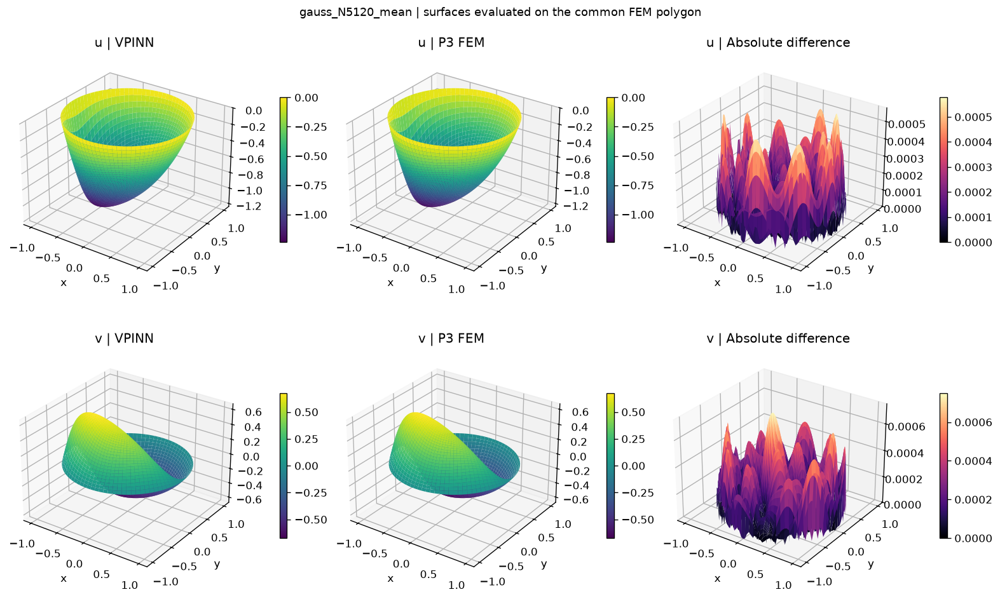

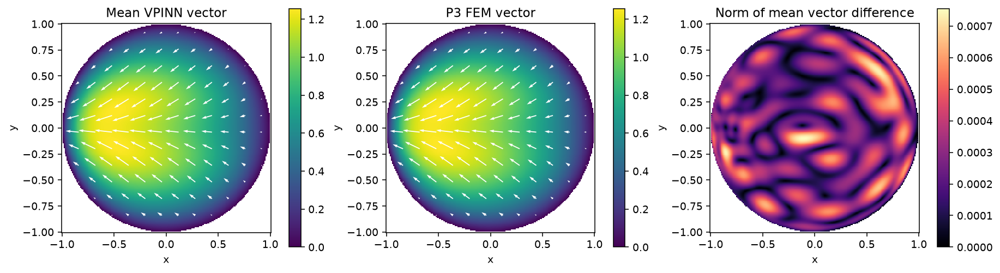

In [32]:
SELECT_N=5120
SELECT_DISTRIBUTION='gauss' # uniform / boundary_weak / boundary_strong / gauss / gauss_boundary_weak / gauss_boundary_strong
prefix=f'{SELECT_DISTRIBUTION}_N{SELECT_N}_mean'
display(Image(filename=f'figures/{prefix}_surface.png'))
display(Image(filename=f'figures/{prefix}_vector.png'))

## 34. 발표에서 연결할 다섯 가지

1. **무엇을 근사하는가:** `VectorDiskNet.forward`의 경계 인자와 독립 두 출력을 설명합니다. 경계조건은 구조적으로 만족하지만 내부 정확도는 학습으로 결정됩니다.
2. **무엇을 최소화하는가:** `Wdx @ grad_x + Wdy @ grad_y`는 확산의 부분적분, `Wpsi @ convection - load`는 대류·하중입니다. 잔차는 190×2 배열이고 Cholesky 풀이가 유한 시험공간의 H1 쌍대 노름을 계산합니다.
3. **구현이 맞는가:** 제조해 검사는 수식 구현, 중요도 적분의 다항식 모멘트 검사는 새 샘플링을 확인합니다. 두 검사는 학습의 성공과 구분합니다.
4. **학습 결과가 정확한가:** 90회 결과는 같은 독립 평가점, 결정론적 적분, 확장 시험공간, 동일한 P3 참조해를 사용합니다. 서로 다른 손실의 수치 크기를 단순 비교하지 않습니다.
5. **어디까지 주장하는가:** 평균±SE는 5개 시드의 평균 추정 변동이며 엄밀한 PDE 오차 상한이 아닙니다. FEM 자체의 메시·형상 오차와 유한 평가점의 한계가 남습니다.

[III. VPINN HTML 자료 열기](index.html)

## 35. Gauss와 랜덤 적분의 직접 비교

90회 전체 결과의 평균·SE를 비교합니다. Gauss에 유리하도록 학습 예산을 변경하거나 가장 좋은 시드를 선택하지 않았습니다. 동일한 시드의 초기 가중치가 같은지 검사합니다. 점 수가 같아도 수치적분 정확도는 같지 않습니다. 특히 비선형 신경망의 적분은 Gauss 규칙에서도 정확성을 보장하지 않으므로 공통 독립 적분으로 검증합니다.

아래 표의 차이는 각 랜덤 조건의 오차에서 Gauss 오차를 뺀 값입니다. 양수이면 Gauss의 오차가 작습니다. 비율은 두 평균의 비율이며 시드별 비율의 평균이 아닙니다. 시드 수가 5개이므로 일반적인 방법 우열로 확대 해석하지 않습니다.

추가 표는 Gauss 세 조건끼리의 차이와 같은 강조 강도의 랜덤 대비 차이를 보여 줍니다. 추가 표의 부호와 비교 기준은 각 표 설명을 따르십시오. 모든 SE는 동일 시드의 차이를 먼저 계산한 뒤 구합니다.

N,랜덤 조건,랜덤 (%),Gauss (%),짝지은 차이 (%p),평균 오차 비율
1280,균등 랜덤,59.46 ± 22.6,0.05879 ± 0.00356,59.4 ± 22.6,1.01e+03
1280,약한 경계 강조,59 ± 16,0.05879 ± 0.00356,58.94 ± 16,1e+03
1280,강한 경계 강조,38.33 ± 2.54,0.05879 ± 0.00356,38.27 ± 2.54,652
2560,균등 랜덤,38.17 ± 13.4,0.05711 ± 0.00432,38.11 ± 13.4,668
2560,약한 경계 강조,15.25 ± 2.5,0.05711 ± 0.00432,15.19 ± 2.5,267
2560,강한 경계 강조,20.85 ± 3.84,0.05711 ± 0.00432,20.79 ± 3.84,365
5120,균등 랜덤,6.796 ± 1.64,0.0591 ± 0.00417,6.737 ± 1.65,115
5120,약한 경계 강조,6.501 ± 1.26,0.0591 ± 0.00417,6.442 ± 1.25,110
5120,강한 경계 강조,7.723 ± 1.42,0.0591 ± 0.00417,7.663 ± 1.42,131


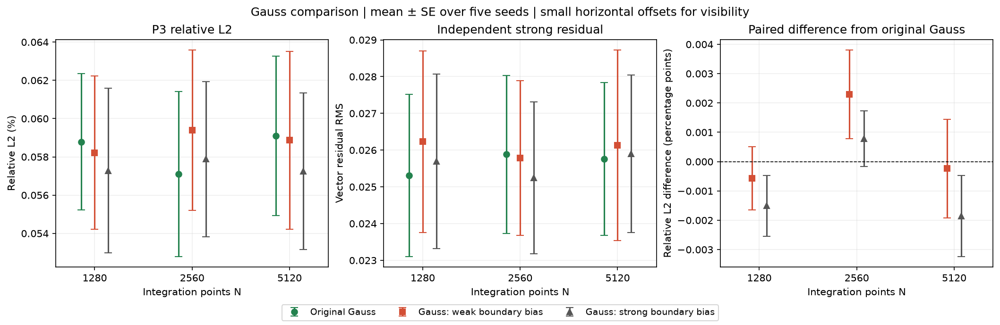

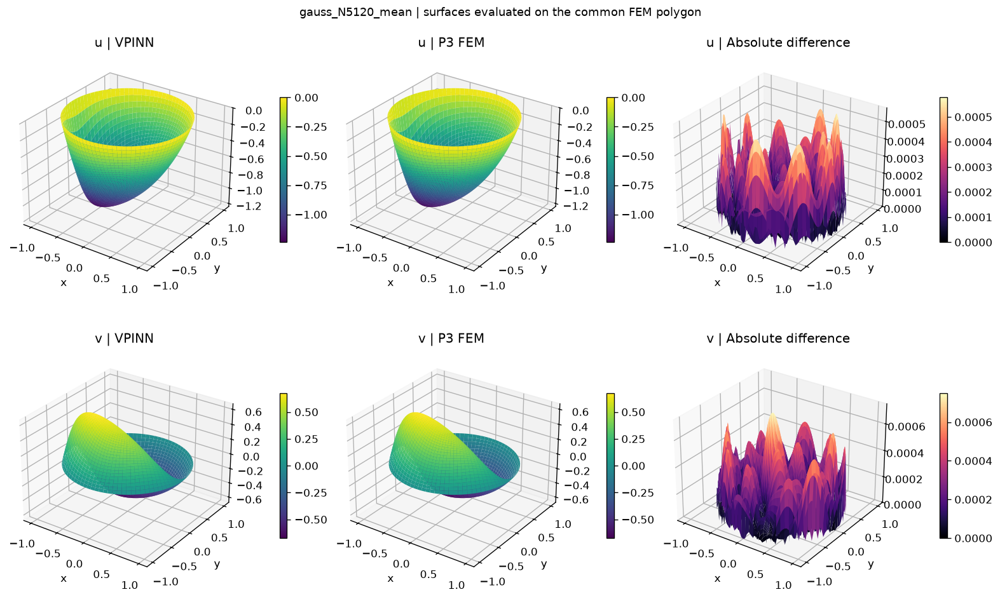

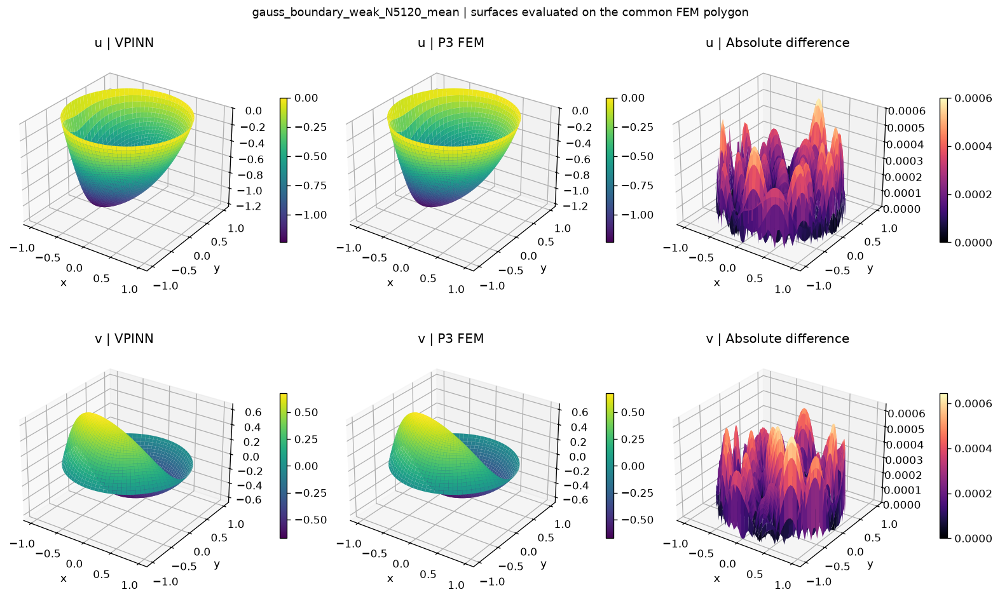

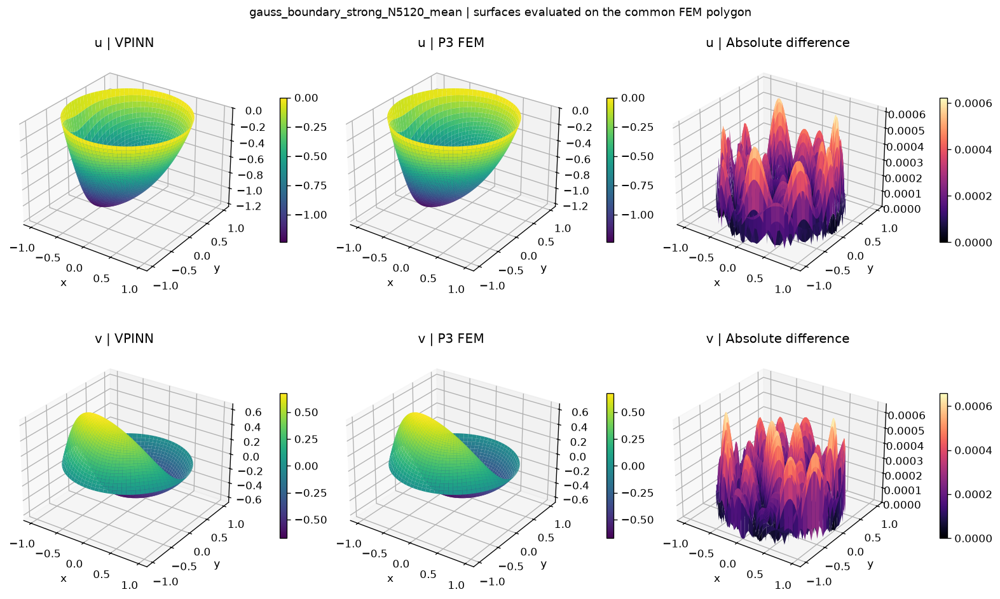

In [33]:

from IPython.display import HTML, Image
display(HTML(Path('gauss_comparison.html').read_text(encoding='utf8')))
display(HTML(Path('boundary_gauss_comparison.html').read_text(encoding='utf8')))
display(Image(filename='figures/boundary_gauss_summary.png'))
for mode in ['gauss','gauss_boundary_weak','gauss_boundary_strong']:
    display(Image(filename=f'figures/{mode}_N5120_mean_surface.png'))


## 36. 학습 시험공간 차원과 작은 epsilon 추가 실험

기본 Gauss 5120점을 고정하고 시험 차수 18/22/26(차원 190/276/378), epsilon 0.1/0.05/0.02, 시드 2026–2030을 교차 비교합니다. 45개 결과 중 기존 기준 모델 5개를 재사용했고 40개를 새로 학습했습니다. 아래 표는 공통 차수 30 검증과 각 epsilon에 맞게 재계산한 P3 비교입니다.

전체 재현 명령은 `python degree_epsilon/run_all.py`입니다. 완료 모델을 재사용하며 새 epsilon의 P3 참조해와 세분화 검사도 포함합니다. 학습은 `degree_epsilon/experiment.py`, 독립 평가는 `degree_epsilon/evaluate.py`, P3 솔버는 `degree_epsilon/p3_reference.py`에 있습니다. 기본 해설은 Gauss 기준이며, 랜덤 배치 비교와 구분합니다.

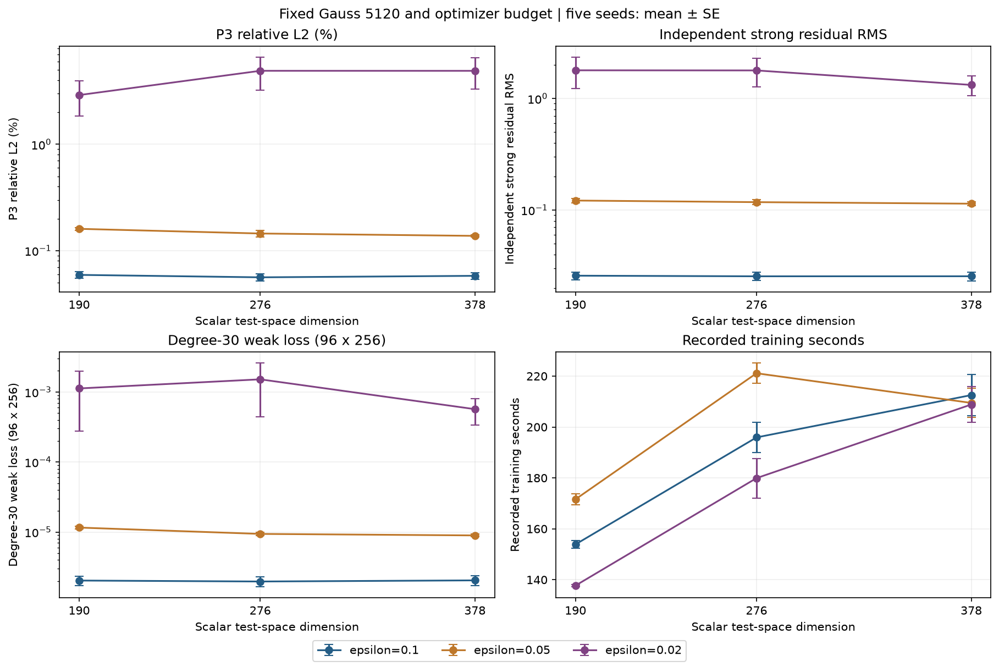

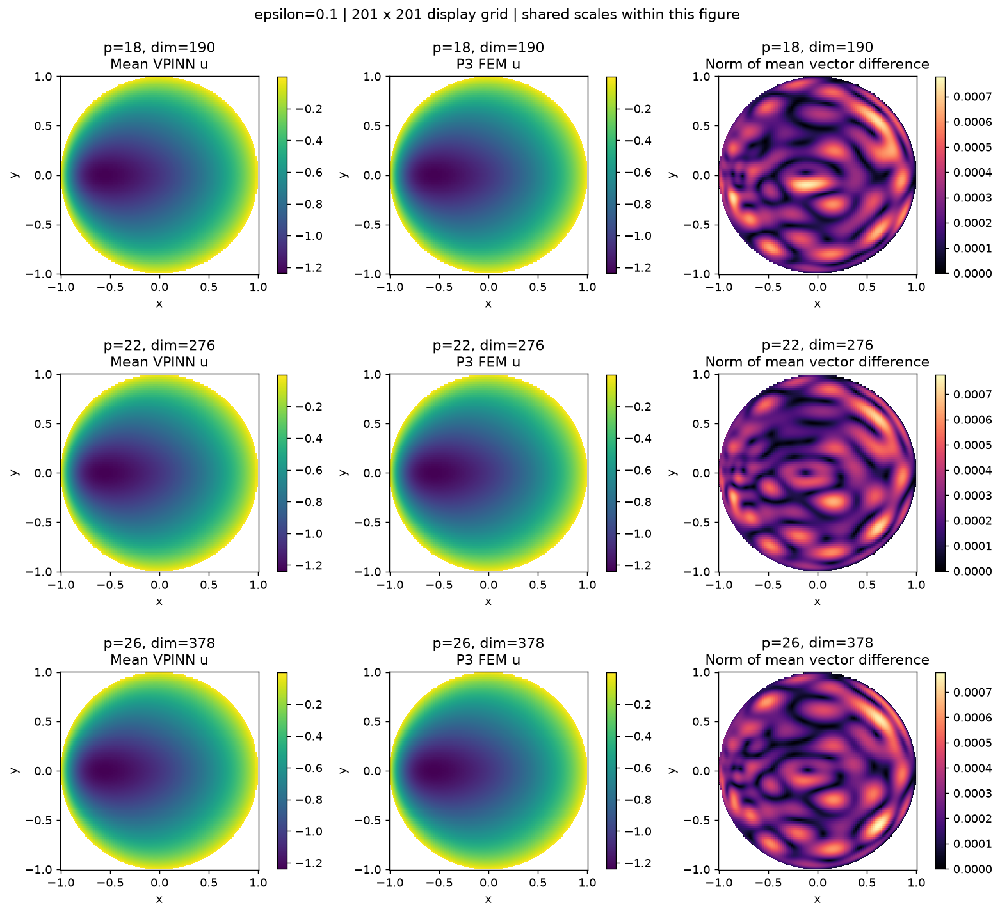

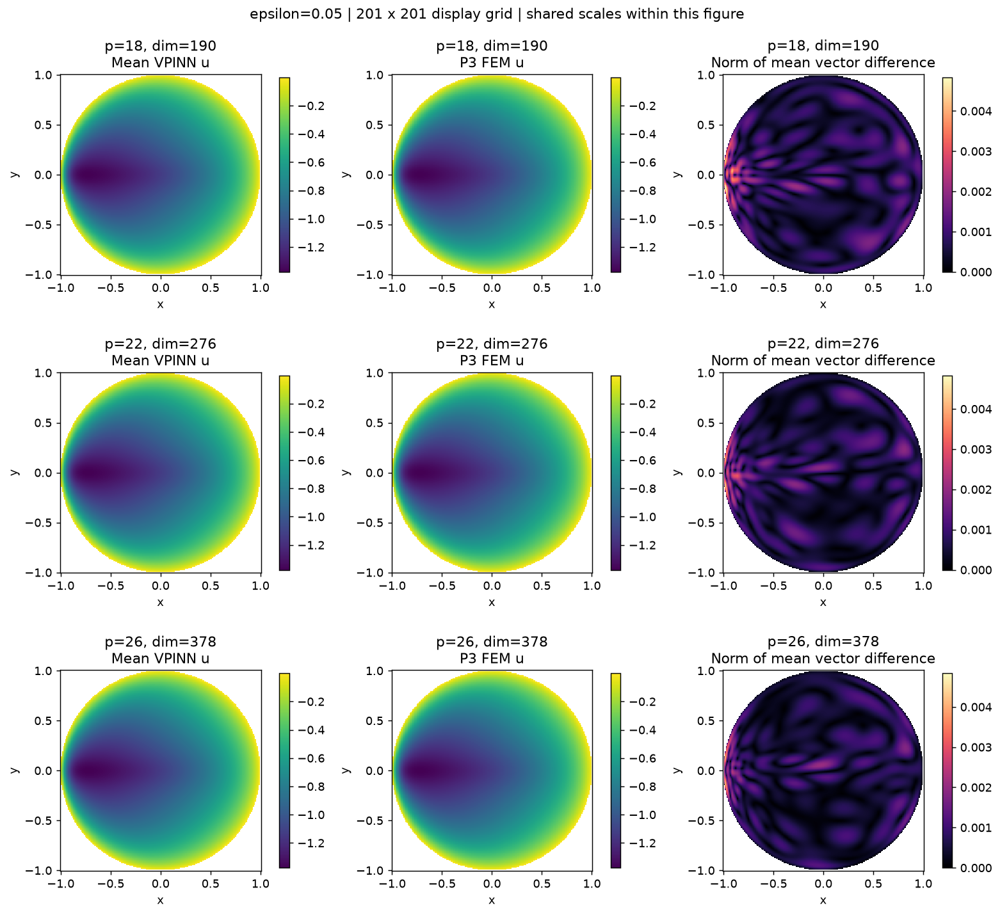

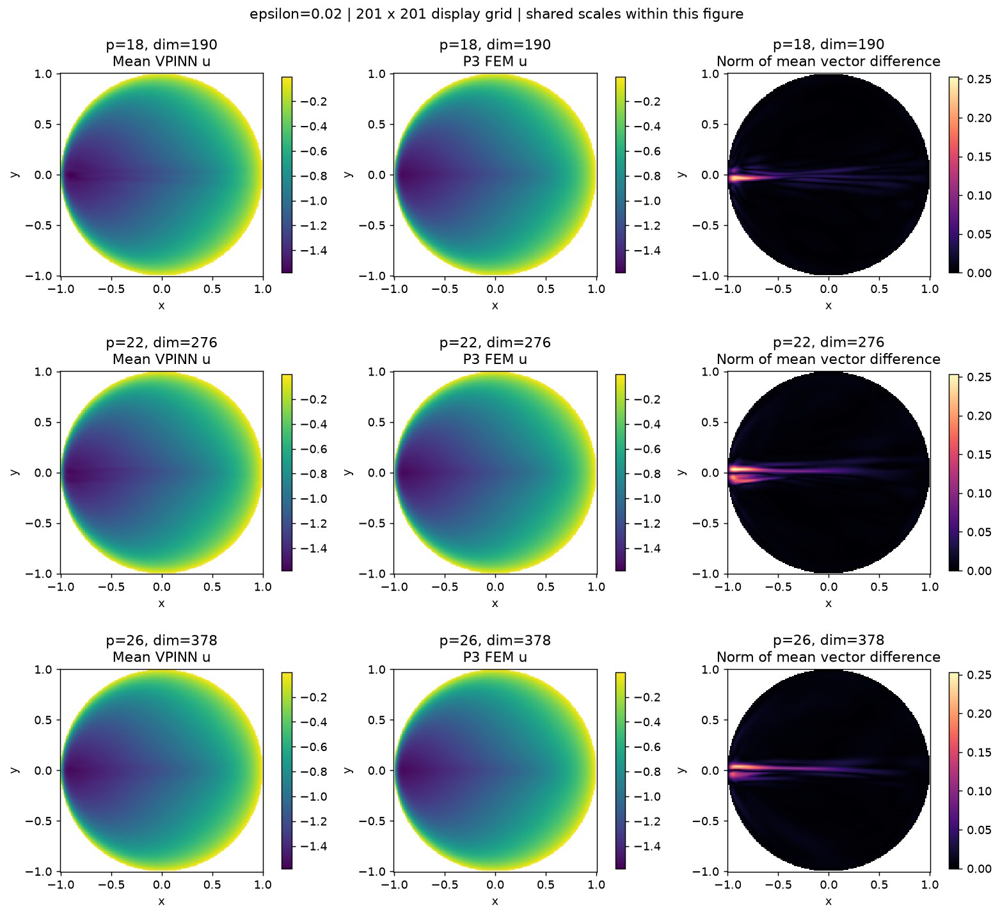

In [1]:
from pathlib import Path
from IPython.display import HTML, Image, display
display(HTML(Path('degree_epsilon/report_tables.html').read_text(encoding='utf8')))
for name in ['dimension_epsilon.png', 'fields_eps0.1.png', 'fields_eps0.05.png', 'fields_eps0.02.png']:
    display(Image(filename=str(Path('degree_epsilon/figures')/name)))